# YOLO11s-seg: entrenamiento y evaluación

Ejecuta las celdas en orden en Google Colab con GPU. Se conservan las rutas,
los nombres de los entrenamientos y los hiperparámetros del cuaderno original.
Se muestran las tablas y las figuras estándar de Ultralytics para cada modelo disponible.
Los pesos, métricas, figuras y predicciones se guardan en `RUNS_DIR`.

## 1. Configuración

In [ ]:
DRIVE_DATASET = '/content/drive/MyDrive/DSP/Dataset/unified_yolo'
SEG_LABELS_EXACT = '/content/drive/MyDrive/DSP/Dataset/seg_labels.zip'
SEG_LABELS_SAM = '/content/drive/MyDrive/DSP/Dataset/seg_labels_sam'
CANVAS_ZIP = '/content/drive/MyDrive/DSP/Dataset/overlap_canvases.zip'
RUNS_DIR = '/content/drive/MyDrive/yolo_runs'
LOCAL_DATA = '/content/data'

TASK = 'segment'
IMGSZ = 1024
EPOCHS = 100
FT_EPOCHS = 40
BATCH_FIJO = 0  # 0: calcular según la memoria de la GPU.
ENTRENAR = False  # False: usar los pesos existentes y evaluar.
ENTRENAR_CONTROL = False
ULTRALYTICS_VERSION = '8.4.192'
N_IMAGENES = 3  # Imágenes de ejemplo por dataset y modelo.
SEED = 0

MODEL_TAG = 'yolo11s-seg' if TASK == 'segment' else 'yolo11s'
SEG = TASK == 'segment'
RUNS = {
    'c1 (1 clase)': f'chromosome1_{MODEL_TAG}_{IMGSZ}',
    'c24 desde COCO': f'chromosome24_{MODEL_TAG}_{IMGSZ}',
    'c24 desde c1': f'chromosome24_{MODEL_TAG}_{IMGSZ}_desde_c1',
    'c1 + lienzos': f'chromosome1_{MODEL_TAG}_{IMGSZ}_ft_lienzos',
    'c1 sin lienzos (control)': f'chromosome1_{MODEL_TAG}_{IMGSZ}_ft_control',
}

## 2. Entorno

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
_pkg = f'ultralytics=={ULTRALYTICS_VERSION}' if ULTRALYTICS_VERSION else 'ultralytics'
%pip install {_pkg}

name, memory.total [MiB]
NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import csv
import glob
import hashlib
import os
import random
import re
import shutil
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import ultralytics
from IPython.display import Image, display
from PIL import Image as PILImage, ImageDraw
from ultralytics import YOLO
from ultralytics.utils.plotting import plot_results

if not torch.cuda.is_available():
    raise RuntimeError('Selecciona una GPU en el entorno de ejecución de Colab.')

vram = torch.cuda.get_device_properties(0).total_memory / 2**30
BATCH = 32 if vram > 35 else 24 if vram > 20 else 16 if vram > 14 else 8
if SEG:
    BATCH = max(4, BATCH * 3 // 4)
if BATCH_FIJO:
    BATCH = BATCH_FIJO

os.makedirs(RUNS_DIR, exist_ok=True)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
print('Ultralytics:', ultralytics.__version__)
print('GPU:', torch.cuda.get_device_name(0))
print('Memoria (GB):', round(vram, 1))
print('Batch:', BATCH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Ultralytics: 8.4.192
GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition
Memoria (GB): 95.0
Batch: 24


## 3. Preparación de datos

In [ ]:
SPLITS = ('train', 'val', 'test')
IMG_EXT = ('.jpg', '.jpeg', '.png')
EXPECTED = {'chromosome24': (3880, 394, 1325), 'chromosome1': (4385, 464, 1398)}  # imágenes por split
CANVAS_DIR = f'{LOCAL_DATA}/overlap_canvases'
SEG_ARGS = {'overlap_mask': False} if SEG else {}


def stem_of(path):
    return os.path.splitext(os.path.basename(path))[0]


def list_images(folder, prefix=''):
    """Imágenes de una carpeta, ordenadas (sin los .npy que deja cache='disk')."""
    if not os.path.isdir(folder):
        return []
    return sorted(os.path.join(folder, f) for f in os.listdir(folder)
                  if f.startswith(prefix) and f.lower().endswith(IMG_EXT))


def find_in_drive(pattern, root='/content/drive/MyDrive'):
    """Primer archivo o carpeta de Drive que encaje con pattern (hasta 4 carpetas de profundidad)."""
    for depth in range(5):
        hits = sorted(glob.glob(f'{root}/{"*/" * depth}{pattern}'))
        if hits:
            return hits[0]
    raise FileNotFoundError(f'No encuentro {pattern} en {root}')


def _count(data_dir, split):
    return (len(list_images(f'{data_dir}/images/{split}')),
            len(glob.glob(f'{data_dir}/labels/{split}/*.txt')))


def _find_source(variant):
    """Carpeta de la variante o .zip en Drive; si DRIVE_DATASET no la tiene, la busca en MyDrive."""
    p = DRIVE_DATASET.rstrip('/')
    if p.endswith('.zip') and os.path.isfile(p):
        return p
    if os.path.isfile(os.path.join(p, variant, 'data.yaml')):
        return os.path.join(p, variant)
    if os.path.isfile(os.path.join(p, 'data.yaml')) and os.path.basename(p) == variant:
        return p
    root = '/content/drive/MyDrive'
    hits = [os.path.dirname(f) for d in range(4) for f in glob.glob(f'{root}/{"*/" * d}{variant}/data.yaml')]
    hits += [f for d in range(4) for f in glob.glob(f'{root}/{"*/" * d}*.zip')
             if re.search(r'unified|chromosome', os.path.basename(f), re.I)]
    if len(hits) == 1:
        return hits[0]
    raise FileNotFoundError(f'No encuentro {variant} en {DRIVE_DATASET}. Candidatos: {hits or "ninguno"}. '
                            'Ajusta DRIVE_DATASET en la configuración.')


def prepare_dataset(variant, task=TASK):
    """Copia la variante de Drive al disco local (si no está ya completa), le pone los polígonos si task='segment'
    y escribe un data_colab.yaml con rutas locales. Devuelve (carpeta, yaml)."""
    data_dir = f'{LOCAL_DATA}/{variant}'
    expected = EXPECTED[variant]
    if not (os.path.isdir(data_dir) and all(_count(data_dir, s) == (n, n) for s, n in zip(SPLITS, expected))):
        src = _find_source(variant)
        print(f'[{variant}] copiando desde {src} ...')
        shutil.rmtree(data_dir, ignore_errors=True)
        os.makedirs(LOCAL_DATA, exist_ok=True)
        if src.endswith('.zip'):
            subprocess.run(['unzip', '-q', '-o', src, '-d', LOCAL_DATA], check=True)
            found = glob.glob(f'{LOCAL_DATA}/**/{variant}/data.yaml', recursive=True)
            if not found:
                raise FileNotFoundError(f'El zip no contiene {variant}/data.yaml')
            if os.path.dirname(found[0]) != data_dir:
                shutil.move(os.path.dirname(found[0]), data_dir)
        else:
            subprocess.run(['cp', '-r', src, data_dir], check=True)
        for f in glob.glob(f'{data_dir}/labels/*.cache'):
            os.remove(f)

    for split, n in zip(SPLITS, expected):
        imgs, labels = _count(data_dir, split)
        print(f'[{variant}] {split:5s}: {imgs} imágenes, {labels} etiquetas (esperado {n})')
        if not imgs == labels == n:
            raise RuntimeError(f'[{variant}] faltan archivos en {split}: revisa la subida a Drive '
                               '(o actualiza EXPECTED si cambiaste el dataset a propósito)')
    with open(f'{data_dir}/data.yaml') as fh:
        yaml_src = fh.read()

    if task == 'segment':
        if not os.path.isfile(SEG_LABELS_EXACT):
            raise FileNotFoundError(f'Falta {SEG_LABELS_EXACT}: sube ahí unified_yolo/seg_labels.zip')
        exact = f'{LOCAL_DATA}/seg_labels/{variant}'
        if not os.path.isdir(exact):
            subprocess.run(['unzip', '-q', '-o', SEG_LABELS_EXACT, '-d', LOCAL_DATA], check=True)
        seg_dir = f'{LOCAL_DATA}/{variant}_seg'
        missing, n_exact, n_sam = [], 0, 0
        for split in SPLITS:
            sam_dir = f'{SEG_LABELS_SAM}/{variant}/{split}'
            sam_files = set(os.listdir(sam_dir)) if os.path.isdir(sam_dir) else set()
            for sub in ('images', 'labels'):
                os.makedirs(f'{seg_dir}/{sub}/{split}', exist_ok=True)
            for path in list_images(f'{data_dir}/images/{split}'):
                f, stem = os.path.basename(path), stem_of(path)
                # Polígonos exactos (AutoKary, solapamientos) si los hay; si no, los de SAM (54816)
                if os.path.exists(f'{exact}/{split}/{stem}.txt'):
                    src, n_exact = f'{exact}/{split}/{stem}.txt', n_exact + 1
                elif stem + '.txt' in sam_files:
                    src, n_sam = f'{sam_dir}/{stem}.txt', n_sam + 1
                else:
                    missing.append(f'{split}/{stem}')
                    continue
                if not os.path.exists(f'{seg_dir}/images/{split}/{f}'):
                    os.link(path, f'{seg_dir}/images/{split}/{f}')  # enlace duro: no ocupa espacio
                shutil.copy(src, f'{seg_dir}/labels/{split}/{stem}.txt')
        if missing:
            raise RuntimeError(f'{len(missing)} imágenes sin polígonos (p. ej. {missing[:3]}). '
                               '¿Terminó sam_54816_colab.ipynb?')
        print(f'[{variant}] polígonos: {n_exact} exactos + {n_sam} de SAM -> {seg_dir}')
        data_dir = seg_dir

    data_yaml = f'{data_dir}/data_colab.yaml'
    with open(data_yaml, 'w') as fh:
        fh.write(re.sub(r'(?m)^path:.*$', f'path: {data_dir}', yaml_src))
    return data_dir, data_yaml


def subset_yaml(data_yaml, name, files):
    """Copia de data_yaml con el split test reducido a la lista de imágenes files."""
    out_dir = f'{LOCAL_DATA}/subsets'
    os.makedirs(out_dir, exist_ok=True)
    with open(f'{out_dir}/{name}.txt', 'w') as fh:
        fh.write('\n'.join(files) + '\n')
    if not files:
        raise ValueError(f'El subconjunto {name} no contiene imágenes.')
    with open(data_yaml) as fh:
        text = re.sub(r'(?m)^test:.*$', f'test: {out_dir}/{name}.txt', fh.read())
    with open(f'{out_dir}/{name}.yaml', 'w') as fh:
        fh.write(text)
    return f'{out_dir}/{name}.yaml'


def ensure_canvases():
    if not os.path.isdir(CANVAS_DIR):
        subprocess.run(['unzip', '-q', '-o', CANVAS_ZIP, '-d', LOCAL_DATA], check=True)


def weights(label, kind='best'):
    return f'{RUNS_DIR}/{RUNS[label]}/weights/{kind}.pt'


def load_models(labels):
    """{nombre: YOLO} de los modelos de la lista que ya existen; los demás se omiten avisando."""
    models = {}
    for label in labels:
        if os.path.exists(weights(label)):
            models[label] = YOLO(weights(label))
        else:
            print(f'{label}: no existe {weights(label)}, se omite')
    return models


def train_or_resume(label, start_weights, data_yaml, **train_args):
    """Entrena el run `label` desde start_weights. Si ya terminó, lo salta; si quedó a medias, lo retoma."""
    run = RUNS[label]
    last, best = weights(label, 'last'), weights(label, 'best')
    if os.path.exists(last):
        if torch.load(last, map_location='cpu', weights_only=False).get('epoch', -1) == -1:
            print(f'{label} ({run}): ya terminó. Para entrenar de nuevo, cambia su nombre en RUNS.')
        elif not ENTRENAR:
            print(f'{label} ({run}): quedó a medias; no se retoma porque ENTRENAR = False.')
        else:
            print(f'{label} ({run}): retomando desde {last}')
            YOLO(last).train(resume=True, data=data_yaml, plots=True, verbose=True, save=True)
        return
    if os.path.exists(best):
        print(f'{label} ({run}): hay best.pt pero no last.pt; no se entrena para no sobrescribirlo.')
        return
    if not ENTRENAR:
        print(f'{label} ({run}): sin entrenar (ENTRENAR = False).')
        return
    if start_weights.startswith('/') and not os.path.exists(start_weights):
        print(f'{label}: falta el modelo de partida {start_weights}; entrena antes ese run.')
        return
    print(f'{label} ({run}): entrenando desde {start_weights}')
    YOLO(start_weights).train(data=data_yaml, imgsz=IMGSZ, batch=BATCH, cache='disk', flipud=0.5,
                              project=RUNS_DIR, name=run, exist_ok=True, plots=True, verbose=True,
                              save=True, **SEG_ARGS, **train_args)


def build_ft_dataset(add_canvases):
    """chromosome1 (enlaces duros) más, si add_canvases, los lienzos de train y val. El test no cambia."""
    ft_dir = f'{LOCAL_DATA}/{RUNS["c1 + lienzos" if add_canvases else "c1 sin lienzos (control)"]}'
    if add_canvases:
        ensure_canvases()
    for split in SPLITS:
        for sub in ('images', 'labels'):
            os.makedirs(f'{ft_dir}/{sub}/{split}', exist_ok=True)
        for src in [C1_DIR] + ([CANVAS_DIR] if add_canvases and split != 'test' else []):
            for f in os.listdir(f'{src}/images/{split}'):
                stem, ext = os.path.splitext(f)
                # .npy = caché de cache='disk' ya hecha para chromosome1 (mismo imgsz): se reutiliza
                if ext.lower() not in IMG_EXT + ('.npy',):
                    continue
                if not os.path.exists(f'{ft_dir}/images/{split}/{f}'):
                    os.link(f'{src}/images/{split}/{f}', f'{ft_dir}/images/{split}/{f}')
                if ext.lower() != '.npy':
                    shutil.copy(f'{src}/labels/{split}/{stem}.txt', f'{ft_dir}/labels/{split}/{stem}.txt')
        imgs = list_images(f'{ft_dir}/images/{split}')
        print(f'{split:5s}: {len(imgs)} imágenes ({sum(stem_of(p).startswith("canvas_") for p in imgs)} lienzos)')
    ft_yaml = f'{ft_dir}/data_colab.yaml'
    with open(ft_yaml, 'w') as fh:
        fh.write(f"path: {ft_dir}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 1\nnames:\n"
                 "  0: 'chromosome'\n")
    return ft_yaml

In [ ]:
DATA = {variant: prepare_dataset(variant) for variant in ('chromosome1', 'chromosome24')}
C1_DIR, C1_YAML = DATA['chromosome1']
C24_DIR, C24_YAML = DATA['chromosome24']
for variant, (_, data_yaml) in DATA.items():
    print(variant)
    print(Path(data_yaml).read_text())

[chromosome1] train: 4385 imágenes, 4385 etiquetas (esperado 4385)
[chromosome1] val  : 464 imágenes, 464 etiquetas (esperado 464)
[chromosome1] test : 1398 imágenes, 1398 etiquetas (esperado 1398)
[chromosome1] polígonos: 1098 exactos + 5149 de SAM -> /content/data/chromosome1_seg
[chromosome24] train: 3880 imágenes, 3880 etiquetas (esperado 3880)
[chromosome24] val  : 394 imágenes, 394 etiquetas (esperado 394)
[chromosome24] test : 1325 imágenes, 1325 etiquetas (esperado 1325)
[chromosome24] polígonos: 605 exactos + 4994 de SAM -> /content/data/chromosome24_seg
chromosome1
# Built by tools/build_unified_yolo.py. Update `path` if you move the folder.
path: /content/data/chromosome1_seg
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: 'chromosome'

chromosome24
# Built by tools/build_unified_yolo.py. Update `path` if you move the folder.
path: /content/data/chromosome24_seg
train: images/train
val: images/val
test: images/test
nc: 24
names:
  0: '1'
  1: '2'
  2:

### Comprobación de las particiones

In [ ]:
# Si una imagen de test de chromosome24 estuviera en el train de chromosome1, el modelo "c24 desde c1" ya la habría
# visto y sus métricas de test saldrían infladas. Se compara el contenido de los archivos (MD5), no solo el nombre.
def md5(path, chunk=1 << 20):
    h = hashlib.md5()
    with open(path, 'rb') as fh:
        for block in iter(lambda: fh.read(chunk), b''):
            h.update(block)
    return h.hexdigest()


where = {}  # hash -> [(variante, split, archivo)]
for variant, (data_dir, _) in DATA.items():
    for split in SPLITS:
        for path in list_images(f'{data_dir}/images/{split}'):
            where.setdefault(md5(path), []).append((variant, split, os.path.basename(path)))

leaks = {}
for hits in where.values():
    for v1, s1, f1 in hits:
        for v2, s2, f2 in hits:
            if s1 < s2:  # cada par de splits distintos una vez
                leaks.setdefault((v1, s1, v2, s2), []).append((f1, f2))
if leaks:
    print('ATENCIÓN: hay imágenes idénticas en splits distintos:')
    for (v1, s1, v2, s2), files in sorted(leaks.items()):
        print(f'  {v1}/{s1} y {v2}/{s2}: {len(files)} (p. ej. {files[0]})')
else:
    print(f'OK: ninguna de las {len(where)} imágenes distintas aparece en dos splits (ni dentro de una variante ni '
          'entre chromosome1 y chromosome24).')

# Los lienzos de train/val del ajuste fino solo deben llevar recortes de train/val
if os.path.isfile(CANVAS_ZIP) or os.path.isdir(CANVAS_DIR):
    ensure_canvases()
    split_of = {stem_of(p): s for s in SPLITS for p in list_images(f'{C1_DIR}/images/{s}', 'overlap_')}
    with open(f'{CANVAS_DIR}/placements.csv') as fh:
        rows = list(csv.DictReader(fh))
    bad = [r for r in rows if split_of.get(r['crop']) != r['split']]
    print(f'Lienzos: {len(rows)} recortes colocados, {len(bad)} en un split distinto al suyo' +
          (f' <-- REVISAR (p. ej. {bad[0]["crop"]} en {bad[0]["split"]})' if bad else ' (OK)'))

OK: ninguna de las 6275 imágenes distintas aparece en dos splits (ni dentro de una variante ni entre chromosome1 y chromosome24).
Lienzos: 1949 recortes colocados, 0 en un split distinto al suyo (OK)


## 4. Entrenamiento

### Una clase, desde COCO

In [ ]:
train_or_resume('c1 (1 clase)', f'{MODEL_TAG}.pt', C1_YAML, epochs=EPOCHS, patience=30)

c1 (1 clase) (chromosome1_yolo11s-seg_1024): ya terminó. Para entrenar de nuevo, cambia su nombre en RUNS.


### 24 clases, desde COCO

In [ ]:
train_or_resume('c24 desde COCO', f'{MODEL_TAG}.pt', C24_YAML, epochs=EPOCHS, patience=30)

c24 desde COCO (chromosome24_yolo11s-seg_1024): sin entrenar (ENTRENAR = False).


### 24 clases, desde el modelo de una clase

In [ ]:
if SEG:
    train_or_resume('c24 desde c1', weights('c1 (1 clase)'), C24_YAML, epochs=EPOCHS, patience=30)

c24 desde c1 (chromosome24_yolo11s-seg_1024_desde_c1): ya terminó. Para entrenar de nuevo, cambia su nombre en RUNS.


### Ajuste fino con lienzos y control opcional

In [ ]:
FT_ARGS = dict(epochs=FT_EPOCHS, patience=15, optimizer='SGD', lr0=0.002, warmup_epochs=1)
if SEG:
    for add_canvases in ([True, False] if ENTRENAR_CONTROL else [True]):
        label = 'c1 + lienzos' if add_canvases else 'c1 sin lienzos (control)'
        train_or_resume(label, weights('c1 (1 clase)'), build_ft_dataset(add_canvases), **FT_ARGS)

train: 4543 imágenes (158 lienzos)
val  : 469 imágenes (5 lienzos)
test : 1398 imágenes (0 lienzos)
c1 + lienzos (chromosome1_yolo11s-seg_1024_ft_lienzos): ya terminó. Para entrenar de nuevo, cambia su nombre en RUNS.


## 5. Resultados de entrenamiento

c1 (1 clase)


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
0,1,745.507,0.80636,1.30580,0.64739,0.95775,0,0.91089,0.91300,0.95667,0.75248,0.91084,0.90405,0.94569,0.63198,0.76618,1.28047,0.54740,0.95653,0,0.000666,0.000666,0.000666
1,2,1431.140,0.77530,1.22282,0.52743,0.94356,0,0.94168,0.92545,0.97197,0.80421,0.93770,0.91284,0.95263,0.68205,0.65885,1.15782,0.46182,0.93312,0,0.001319,0.001319,0.001319
2,3,2125.060,0.77026,1.20532,0.50812,0.94151,0,0.94655,0.93347,0.97742,0.79312,0.94294,0.92728,0.96582,0.67819,0.72705,1.16190,0.45875,0.93402,0,0.001960,0.001960,0.001960
3,4,2814.230,0.75150,1.17134,0.48725,0.93569,0,0.95882,0.93977,0.98121,0.80494,0.95450,0.93149,0.97008,0.71316,0.68208,1.10707,0.42850,0.92803,0,0.001941,0.001941,0.001941
4,5,3519.490,0.73060,1.12971,0.46583,0.92775,0,0.94446,0.93514,0.97643,0.80739,0.93901,0.92652,0.96515,0.68590,0.67832,1.10730,0.44488,0.93402,0,0.001921,0.001921,0.001921
5,6,4212.290,0.71517,1.11790,0.45436,0.92591,0,0.95607,0.94624,0.98299,0.83459,0.95423,0.93817,0.97314,0.72764,0.61685,1.02467,0.38952,0.90842,0,0.001901,0.001901,0.001901
6,7,4908.530,0.70206,1.09650,0.44100,0.91969,0,0.87290,0.70454,0.81691,0.62618,0.85967,0.67600,0.77148,0.46351,0.95063,2.00613,0.97146,1.10705,0,0.001881,0.001881,0.001881
7,8,5598.160,0.69764,1.09009,0.43677,0.91760,0,0.95250,0.94629,0.98062,0.82497,0.95002,0.93961,0.97048,0.72320,0.63776,1.04688,0.40826,0.91510,0,0.001861,0.001861,0.001861
8,9,6286.610,0.69365,1.07517,0.42727,0.91625,0,0.95787,0.93436,0.97704,0.82622,0.95105,0.92725,0.96816,0.72342,0.62432,1.04315,0.41166,0.91232,0,0.001842,0.001842,0.001842
9,10,6967.350,0.68289,1.05569,0.41875,0.91261,0,0.96529,0.95706,0.98688,0.83987,0.95999,0.95057,0.97663,0.73289,0.61387,1.00041,0.36384,0.90310,0,0.001822,0.001822,0.001822


confusion_matrix_normalized.png


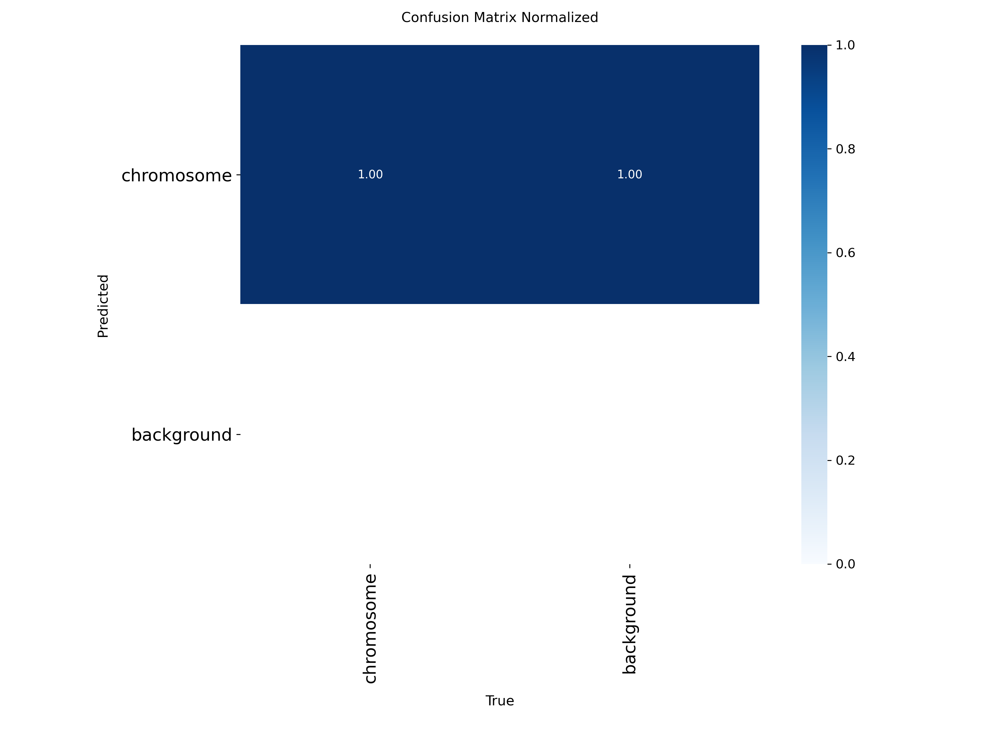

labels.jpg


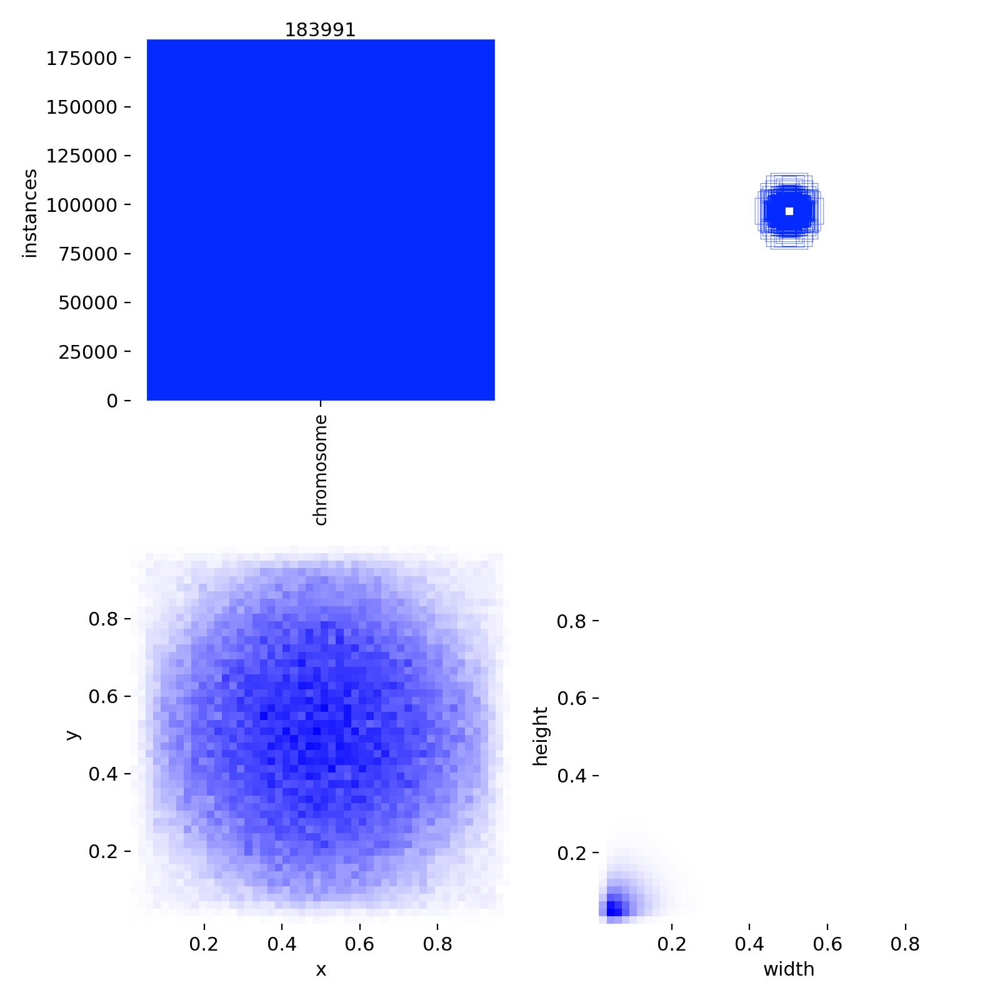

results.png


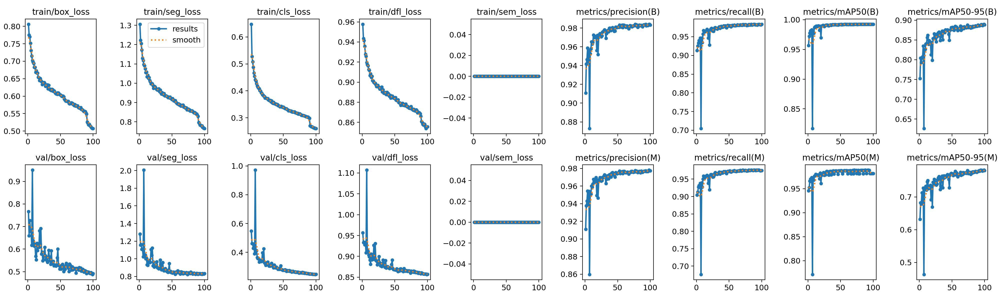

train_batch0.jpg


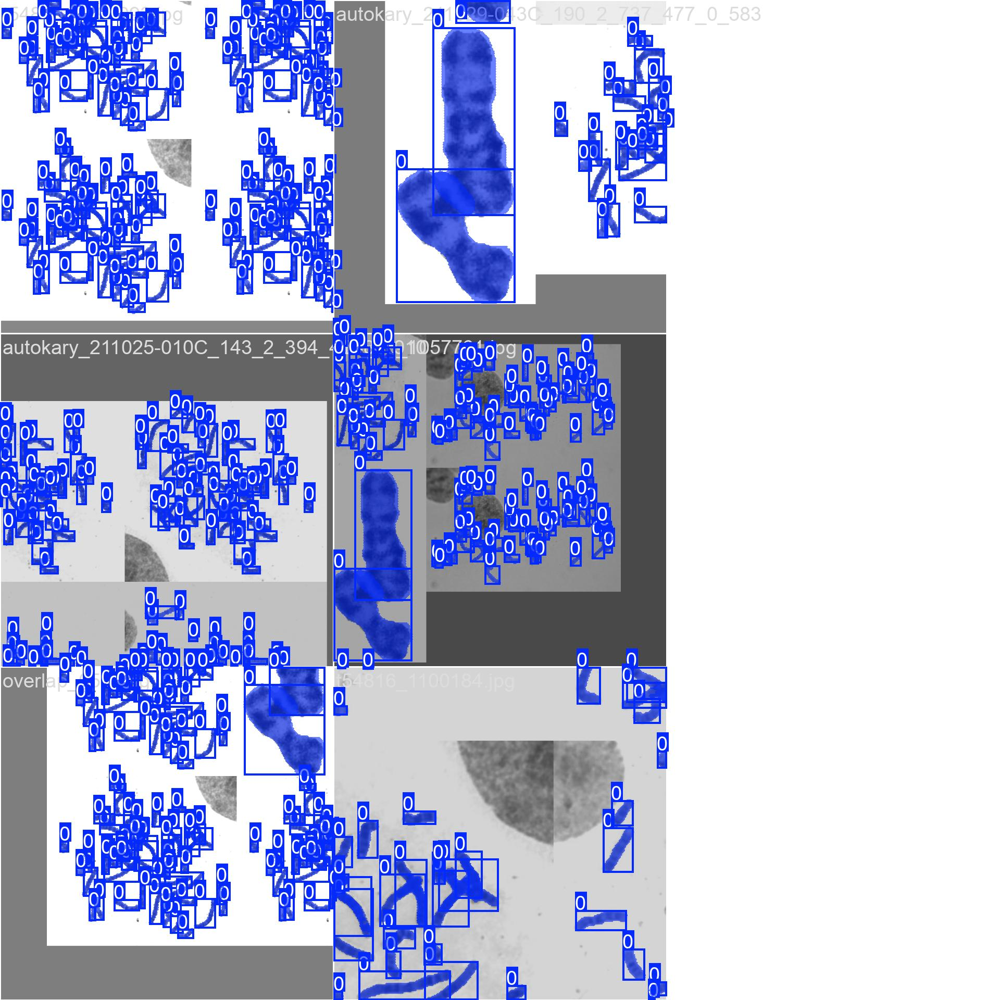

val_batch0_pred.jpg


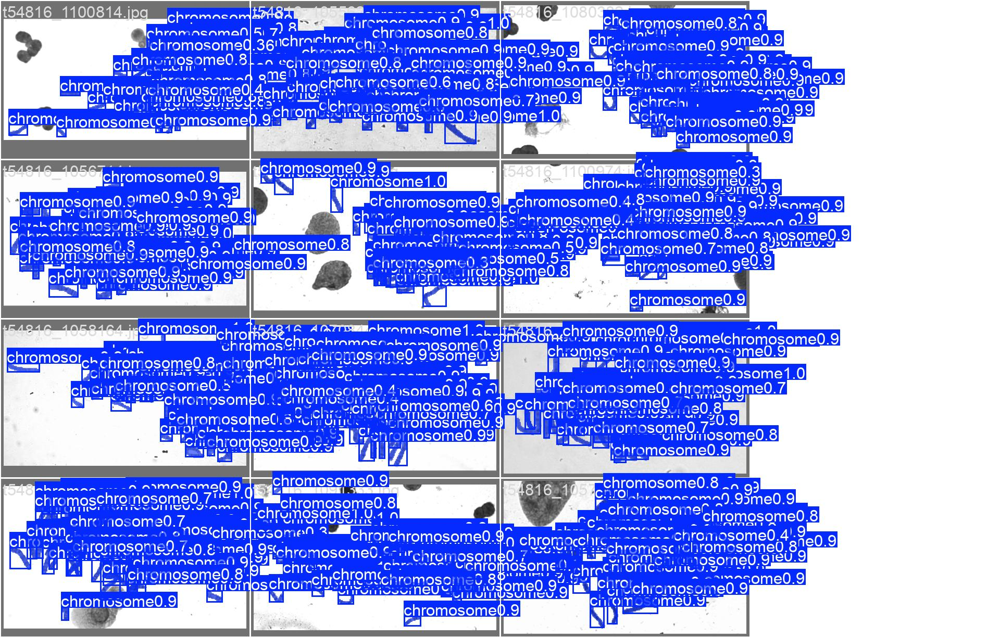

c24 desde COCO
Sin results.csv: /content/drive/MyDrive/yolo_runs/chromosome24_yolo11s-seg_1024/results.csv
c24 desde c1


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
0,1,201.8390,0.60021,0.83888,3.60635,0.89582,0,0.09584,0.58407,0.09417,0.07755,0.09540,0.58189,0.09311,0.06996,0.55045,0.84064,2.40024,0.92964,0,0.000118,0.000118,0.000118
1,2,347.5920,0.58965,0.84228,2.08776,0.90719,0,0.28565,0.61244,0.34569,0.28869,0.28450,0.60983,0.34320,0.25392,0.57565,0.88226,1.62985,0.92496,0,0.000235,0.000235,0.000235
2,3,509.0990,0.57940,0.84804,1.60318,0.90157,0,0.40644,0.64054,0.50280,0.40965,0.40476,0.63735,0.49830,0.35503,0.64802,0.95389,1.38157,0.95037,0,0.000349,0.000349,0.000349
3,4,661.9490,0.57730,0.84919,1.37074,0.90023,0,0.55956,0.73090,0.68320,0.59238,0.55713,0.72593,0.67703,0.52092,0.51301,0.85112,1.03038,0.89754,0,0.000346,0.000346,0.000346
4,5,819.2830,0.57327,0.84476,1.25762,0.89679,0,0.63745,0.74751,0.73721,0.64059,0.63442,0.74323,0.73053,0.56714,0.50974,0.83418,0.93098,0.89481,0,0.000343,0.000343,0.000343
5,6,977.2300,0.57253,0.84611,1.18451,0.89798,0,0.65295,0.73728,0.74563,0.64015,0.64968,0.73311,0.73914,0.56085,0.54022,0.86092,0.92538,0.90705,0,0.000339,0.000339,0.000339
6,7,1134.5900,0.56639,0.83931,1.12912,0.89434,0,0.72432,0.76941,0.80762,0.68925,0.72207,0.76460,0.80054,0.60986,0.56321,0.87117,0.81649,0.91060,0,0.000336,0.000336,0.000336
7,8,1285.0500,0.56635,0.83841,1.06497,0.89497,0,0.73697,0.77356,0.81881,0.71090,0.73431,0.76862,0.81144,0.62841,0.51392,0.83977,0.78465,0.89370,0,0.000332,0.000332,0.000332
8,9,1438.3000,0.56255,0.83653,1.00872,0.89198,0,0.75287,0.77196,0.83078,0.70545,0.75521,0.76290,0.82305,0.62123,0.57916,0.88150,0.78747,0.91697,0,0.000329,0.000329,0.000329
9,10,1594.7500,0.56662,0.84342,0.96462,0.89442,0,0.80487,0.79838,0.87218,0.75414,0.80149,0.79244,0.86386,0.66809,0.53084,0.84568,0.69282,0.90252,0,0.000325,0.000325,0.000325


confusion_matrix_normalized.png


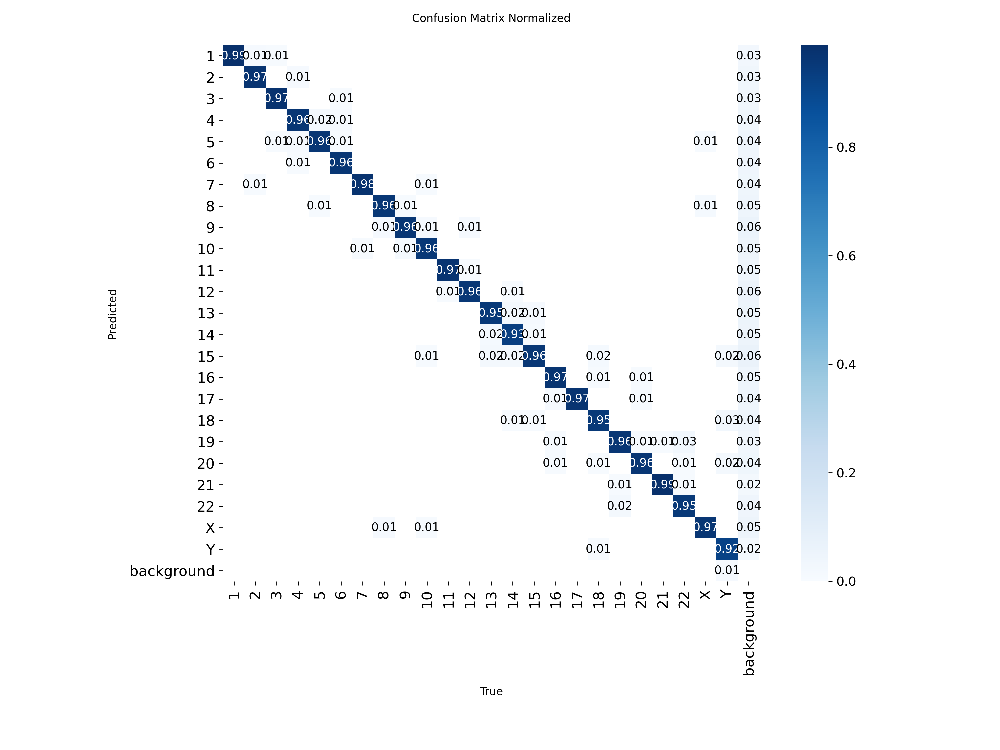

labels.jpg


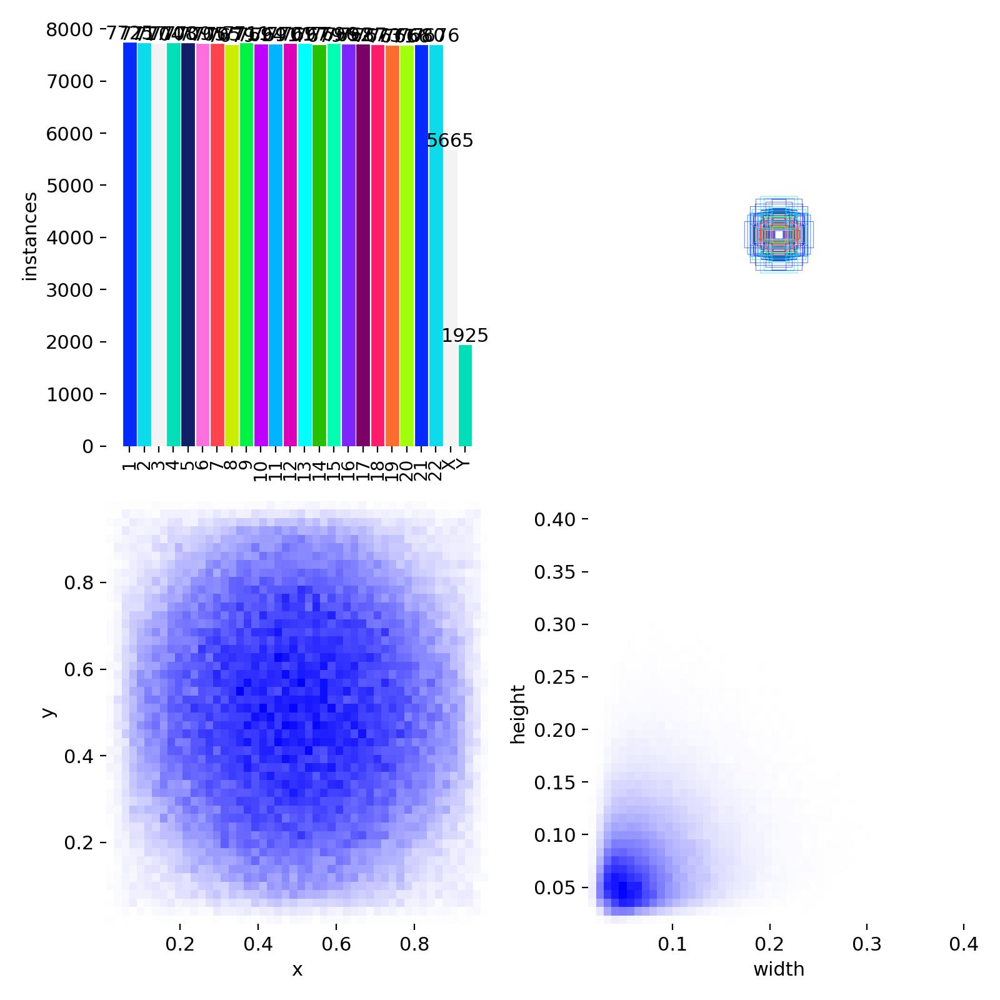

results.png


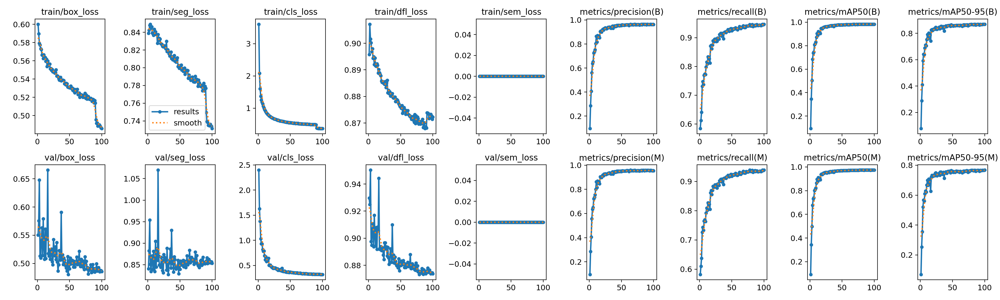

train_batch0.jpg


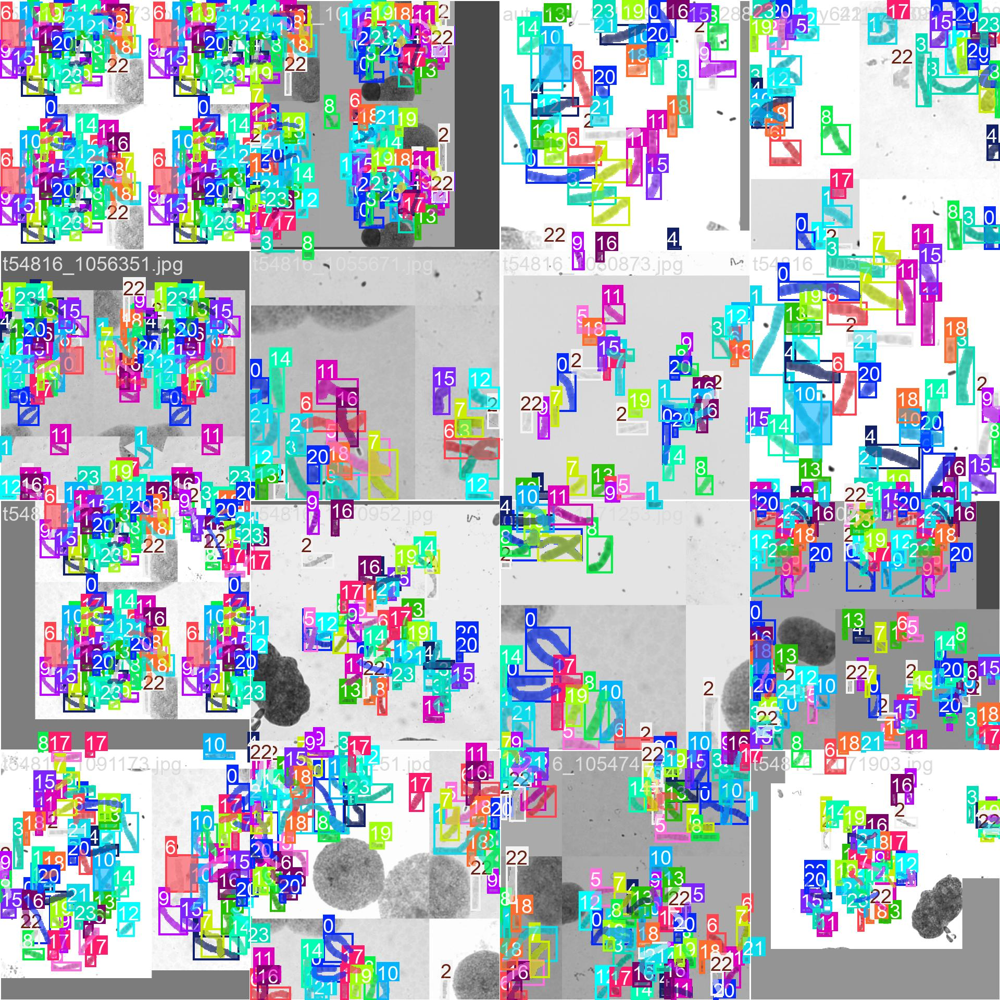

val_batch0_pred.jpg


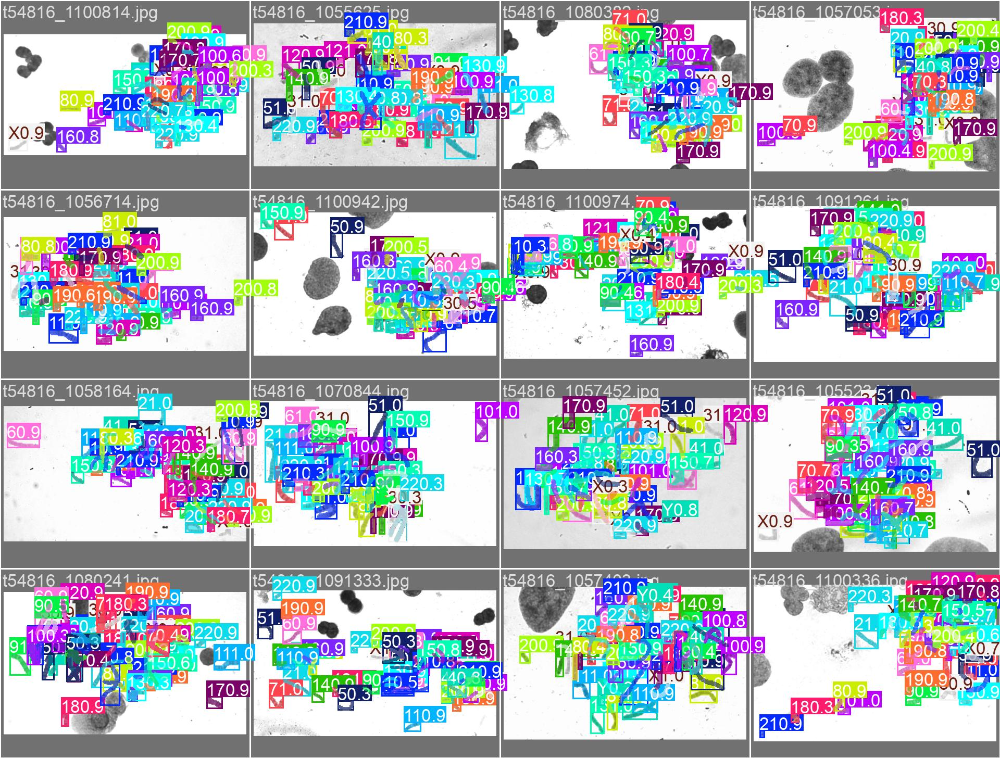

c1 + lienzos


,epoch,time,train/box_loss,train/seg_loss,train/cls_loss,train/dfl_loss,train/sem_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),val/box_loss,val/seg_loss,val/cls_loss,val/dfl_loss,val/sem_loss,lr/pg0,lr/pg1,lr/pg2
0,1,205.580,0.54995,0.83893,0.30188,0.86636,0,0.97919,0.97519,0.99065,0.85617,0.97236,0.96810,0.97957,0.73136,0.58067,0.95095,0.28285,0.88402,0,0.001989,0.001989,0.002516
1,2,363.337,0.54982,0.83129,0.30209,0.86707,0,0.95794,0.89493,0.93814,0.74824,0.95044,0.88616,0.92671,0.59672,0.79041,1.42606,0.51084,0.96999,0,0.001950,0.001950,0.001950
2,3,528.348,0.55008,0.82688,0.30241,0.86651,0,0.90272,0.74853,0.82800,0.57777,0.88757,0.73397,0.79995,0.39342,1.15278,2.24204,0.96758,1.16329,0,0.001901,0.001901,0.001901
3,4,686.364,0.54688,0.82106,0.30178,0.86455,0,0.97405,0.96910,0.98871,0.82435,0.96645,0.96092,0.97776,0.70021,0.67337,1.06697,0.31126,0.90961,0,0.001852,0.001852,0.001852
4,5,849.088,0.54794,0.82285,0.30197,0.86623,0,0.96984,0.95323,0.97933,0.75301,0.96103,0.94457,0.96780,0.60071,0.88308,1.37696,0.38830,0.97766,0,0.001802,0.001802,0.001802
5,6,1013.570,0.54582,0.81811,0.30208,0.86475,0,0.97773,0.97466,0.99094,0.85667,0.97149,0.96818,0.97994,0.74104,0.57560,0.93187,0.28955,0.88313,0,0.001752,0.001752,0.001752
6,7,1177.910,0.54505,0.81896,0.30098,0.86637,0,0.98147,0.97780,0.99160,0.86781,0.97475,0.97031,0.98083,0.75563,0.55051,0.88407,0.26977,0.87516,0,0.001703,0.001703,0.001703
7,8,1342.560,0.54368,0.81320,0.29868,0.86529,0,0.96069,0.90222,0.94188,0.74254,0.95068,0.88983,0.92725,0.59506,0.83575,1.43065,0.47455,0.98821,0,0.001654,0.001654,0.001654
8,9,1503.960,0.54516,0.81878,0.29892,0.86413,0,0.97575,0.95958,0.98294,0.80491,0.96837,0.95139,0.97151,0.66608,0.71866,1.12372,0.34824,0.92320,0,0.001604,0.001604,0.001604
9,10,1667.780,0.54262,0.81453,0.29931,0.86375,0,0.97573,0.97154,0.98947,0.84817,0.96878,0.96415,0.97884,0.72431,0.60438,0.97881,0.29407,0.89472,0,0.001554,0.001554,0.001554


confusion_matrix_normalized.png


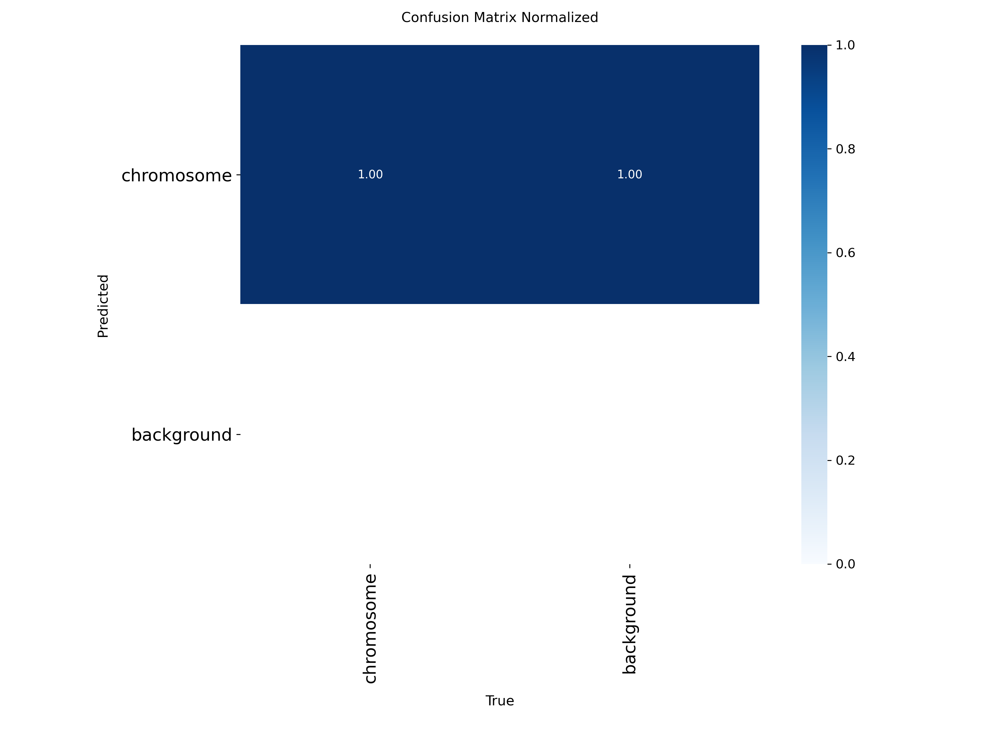

labels.jpg


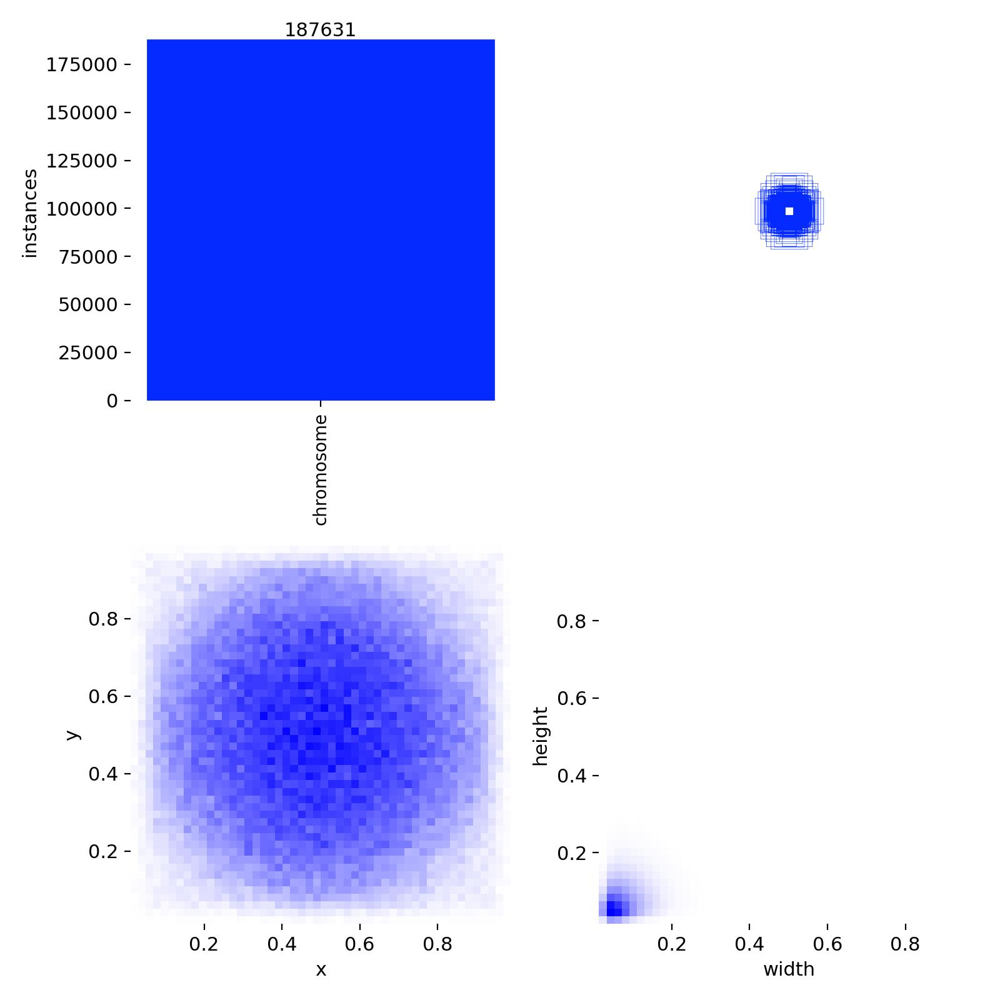

results.png


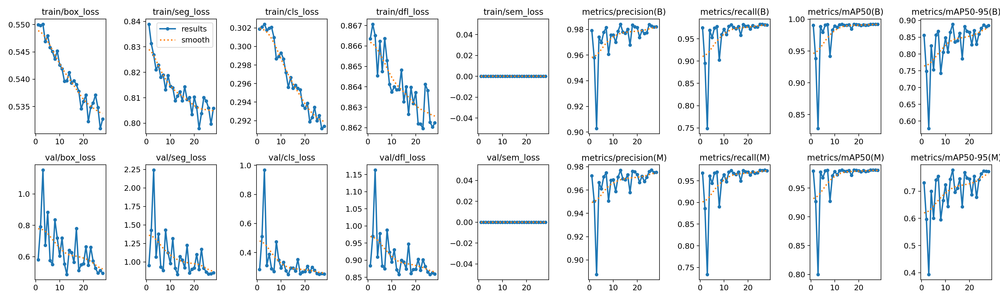

train_batch0.jpg


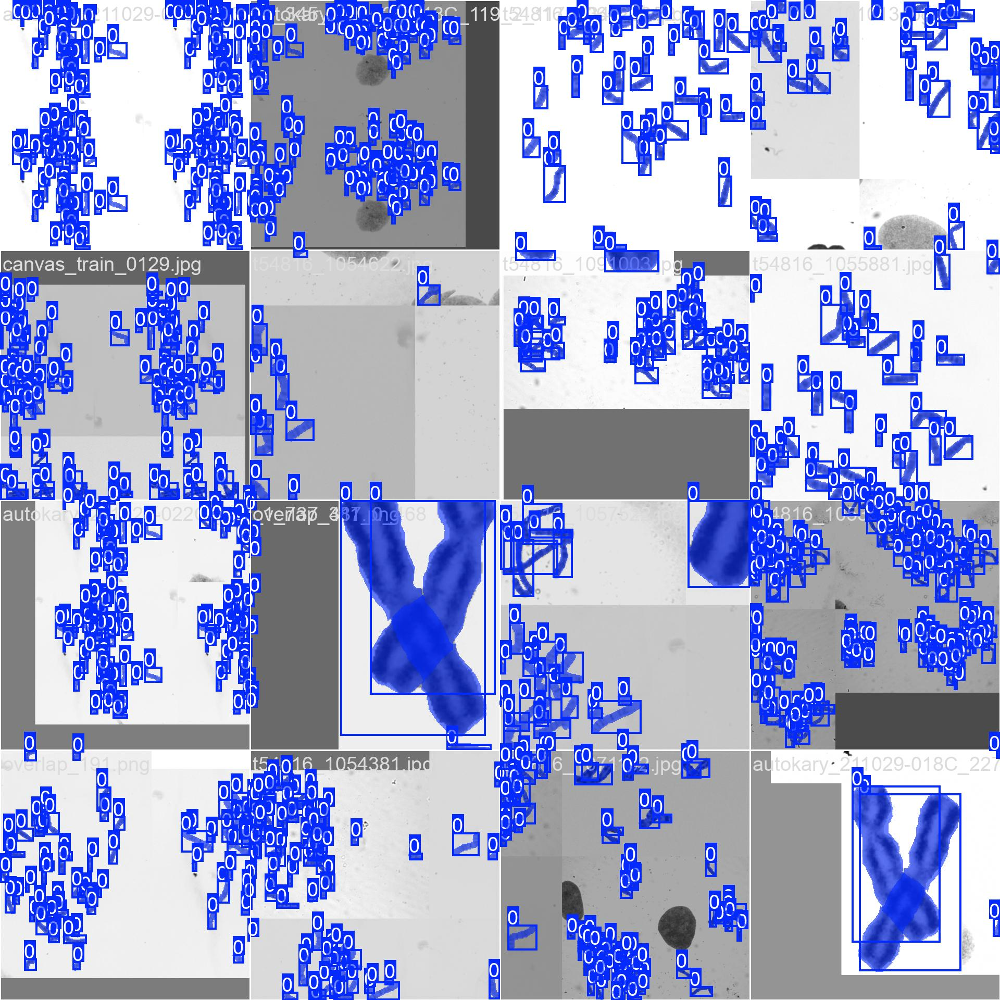

val_batch0_pred.jpg


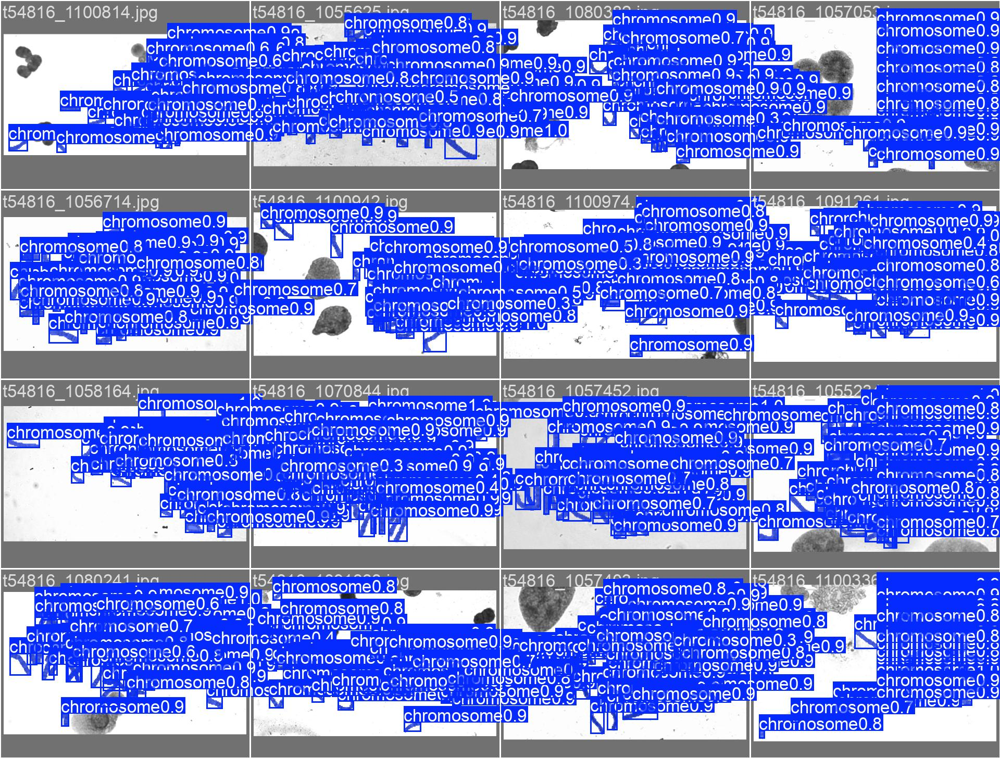

c1 sin lienzos (control)
Sin results.csv: /content/drive/MyDrive/yolo_runs/chromosome1_yolo11s-seg_1024_ft_control/results.csv


In [ ]:
# Solo se muestran las figuras más representativas de cada fase para que el notebook no pese demasiado.
# Todas las figuras siguen guardadas en la carpeta de cada run.
FIGURAS_A_MOSTRAR = ['confusion_matrix_normalized.png', 'labels.jpg', 'results.png', 'train_batch0.jpg', 'val_batch0_pred.jpg']


def mostrar_figuras(folder, patterns=('*.png', '*.jpg', '*.jpeg')):
    paths = sorted({p for pattern in patterns for p in Path(folder).glob(pattern) if p.is_file()})
    if not paths:
        print('Sin figuras:', folder)
    for path in paths:
        if path.name not in FIGURAS_A_MOSTRAR:
            continue
        print(path.name)
        display(Image(filename=str(path)))


for label, run in RUNS.items():
    folder = Path(RUNS_DIR) / run
    csv_path = folder / 'results.csv'
    print(label)
    if not csv_path.exists():
        print('Sin results.csv:', csv_path)
        continue
    history = pd.read_csv(csv_path)
    history.columns = history.columns.str.strip()
    display(history)
    if not (folder / 'results.png').exists():
        plot_results(file=str(csv_path))
    mostrar_figuras(folder)

## 6. Evaluación en test

Se muestran las métricas globales y por clase, las matrices de confusión,
las curvas y los ejemplos de etiquetas y predicciones que genera Ultralytics.
El test completo de c1 incluye solapamientos; el de c24 contiene AutoKary y 54816.

,modelo,best.pt,disponible
0,c1 (1 clase),/content/drive/MyDrive/yolo_runs/chromosome1_y...,True
1,c24 desde COCO,/content/drive/MyDrive/yolo_runs/chromosome24_...,False
2,c24 desde c1,/content/drive/MyDrive/yolo_runs/chromosome24_...,True
3,c1 + lienzos,/content/drive/MyDrive/yolo_runs/chromosome1_y...,True
4,c1 sin lienzos (control),/content/drive/MyDrive/yolo_runs/chromosome1_y...,False


c1 (1 clase) | test_completo
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5064.9±2769.9 MB/s, size: 75.0 KB)
val: Scanning /content/data/chromosome1_seg/labels/test... 1398 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1398/1398 1.1Kit/s 1.3s
val: /content/data/chromosome1_seg/images/test/t54816_1050122.jpg: 1 duplicate labels removed
val: /content/data/chromosome1_seg/images/test/t54816_1050861.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome1_seg/images/test/t54816_1050922.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome1_seg/images/test/t54816_1051072.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome1_seg/images/test/t54816_1051131.jpg: 1 duplicate labels removed
val: /content/data/chromosome1_seg/images/test/t5481

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 (1 clase),test_completo,0.989638,0.9892,0.993777,0.907051,0.953707,0.949251,0.952825,0.737234,1.644284,0.577211,2.8035,0.000557,0.627627


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_test_completo/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,chromosome,0.989638,0.989200,0.993777,0.907051
1,máscaras,0,chromosome,0.953707,0.949251,0.952825,0.737234


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_test_completo/metricas_por_clase.csv
confusion_matrix_normalized.png


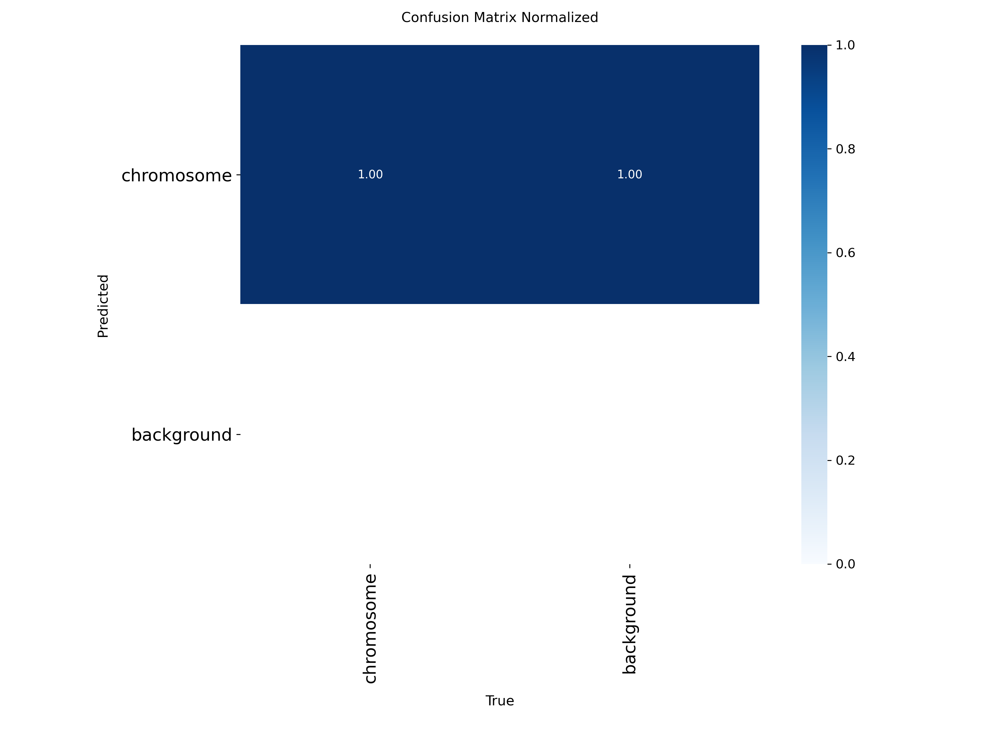

val_batch0_pred.jpg


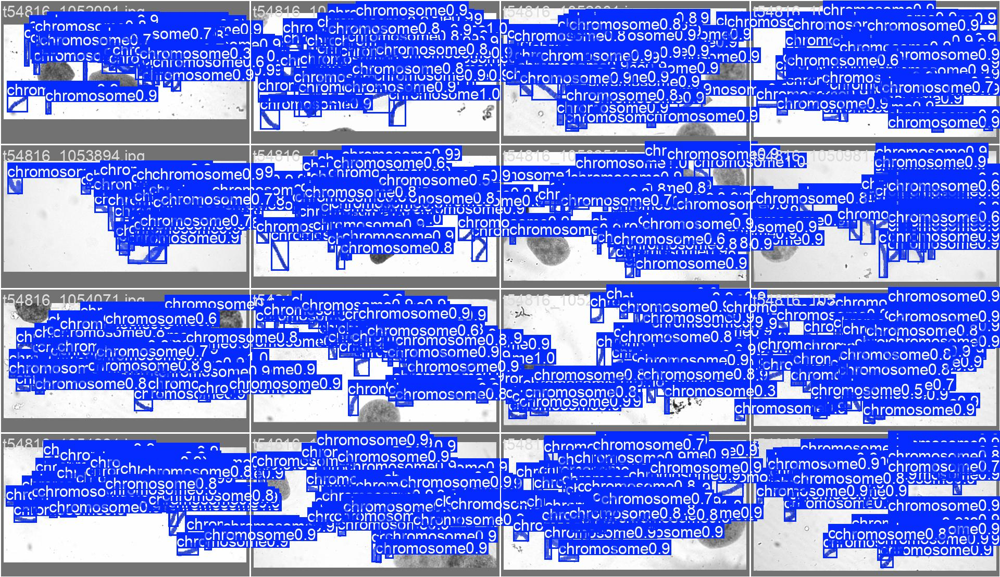

c1 (1 clase) | test_autokary
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 13832.1±1922.6 MB/s, size: 2455.8 KB)
val: Scanning /content/data/chromosome1_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 345.3it/s 0.2s
val: New cache created: /content/data/chromosome1_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3it/s 3.0s
                   all         75       3212      0.978      0.985      0.993      0.847      0.976      0.983      0.992      0.763
Speed: 3.9ms preprocess, 5.2ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovT

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 (1 clase),test_autokary,0.978092,0.984745,0.992523,0.847024,0.97572,0.983188,0.991921,0.763067,1.610091,3.914586,5.161952,0.000277,1.489364


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_test_autokary/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,chromosome,0.978092,0.984745,0.992523,0.847024
1,máscaras,0,chromosome,0.975720,0.983188,0.991921,0.763067


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_test_autokary/metricas_por_clase.csv
confusion_matrix_normalized.png


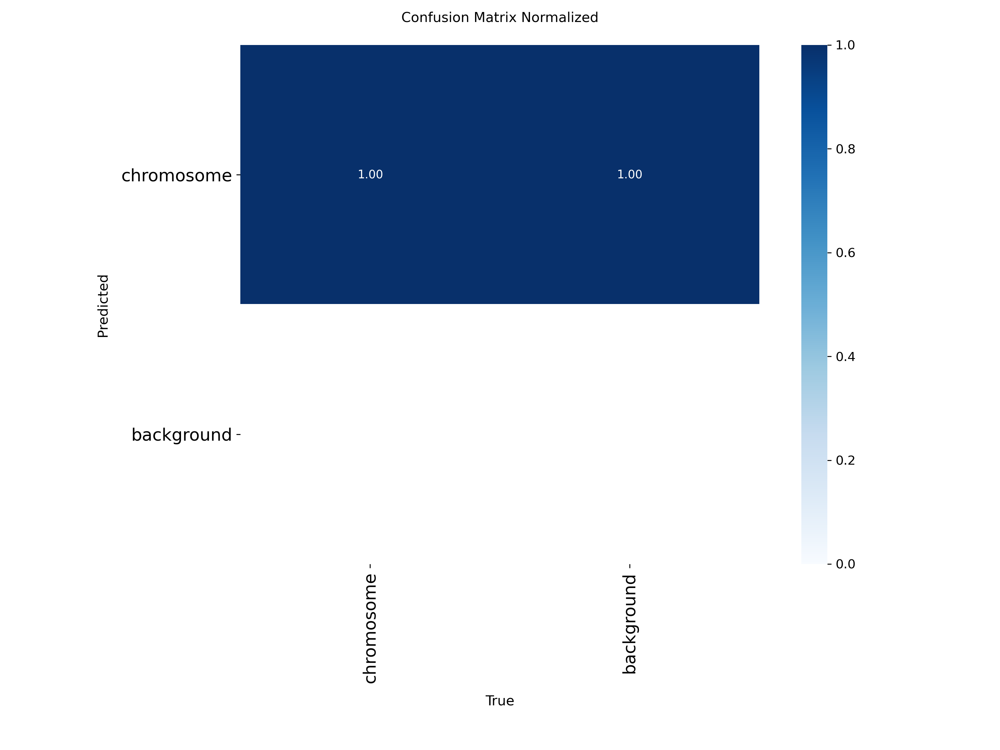

c24 desde c1 | test_completo
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4051.0±962.9 MB/s, size: 80.6 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 1325 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1325/1325 1.1Kit/s 1.2s
val: /content/data/chromosome24_seg/images/test/t54816_1050861.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1050922.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1051072.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1051162.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/images/test/t54816_1051851.jpg: corrupt JPEG restored and saved
val: /content/data/chromosome24_seg/i

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,test_completo,0.969862,0.954701,0.987316,0.887593,0.938889,0.917445,0.940749,0.728792,1.616385,0.590249,2.384741,0.000716,0.573471


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_test_completo/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,1,0.971802,0.984127,0.993088,0.926171
1,cajas,1,2,0.981420,0.980418,0.992086,0.937472
2,cajas,2,3,0.971296,0.975748,0.992229,0.940742
3,cajas,3,4,0.953543,0.963327,0.987912,0.935004
4,cajas,4,5,0.950592,0.957672,0.986123,0.928539
5,cajas,5,6,0.979114,0.964813,0.990879,0.934335
6,cajas,6,7,0.986237,0.975287,0.993440,0.914536
7,cajas,7,8,0.966404,0.948864,0.985755,0.914002
8,cajas,8,9,0.960937,0.955732,0.987444,0.910319
9,cajas,9,10,0.957645,0.943268,0.984897,0.913807


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_test_completo/metricas_por_clase.csv
confusion_matrix_normalized.png


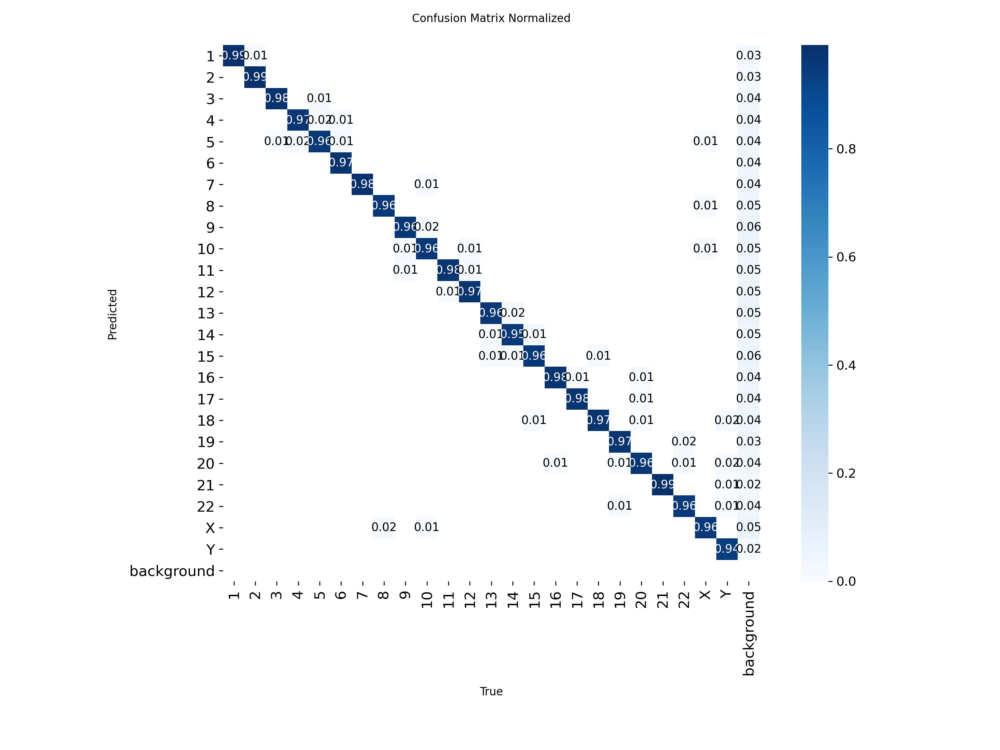

val_batch0_pred.jpg


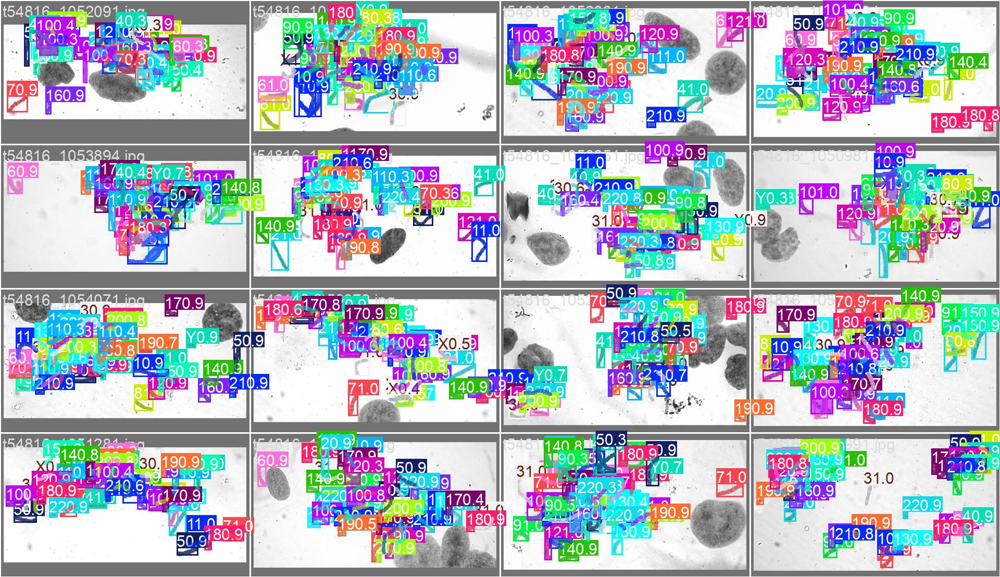

c24 desde c1 | test_autokary
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 15024.8±4505.1 MB/s, size: 2335.0 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 339.1it/s 0.2s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.6it/s 2.5s
                   all         75       3208      0.945      0.914      0.957      0.806      0.944      0.914      0.958      0.731
                     1         74        147      0.986      0.986      0.995      0.924      0.979       0.98      0.994      0.787
                     2        

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,test_autokary,0.94465,0.914218,0.957209,0.806337,0.944374,0.9145,0.957658,0.73136,1.537697,3.62911,2.803138,0.003665,1.401509


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_test_autokary/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,1,0.986378,0.986395,0.994799,0.923687
1,cajas,1,2,0.985580,0.976411,0.990755,0.917300
2,cajas,2,3,0.950248,0.964029,0.969554,0.888775
3,cajas,3,4,0.944928,0.951389,0.974792,0.901814
4,cajas,4,5,0.965413,0.958904,0.982457,0.892733
5,cajas,5,6,0.977860,0.965035,0.981891,0.883096
6,cajas,6,7,0.987668,0.972222,0.992560,0.881790
7,cajas,7,8,0.932373,0.942857,0.976872,0.864408
8,cajas,8,9,0.930932,0.902778,0.947839,0.822402
9,cajas,9,10,0.923758,0.896552,0.959077,0.853124


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_test_autokary/metricas_por_clase.csv
confusion_matrix_normalized.png


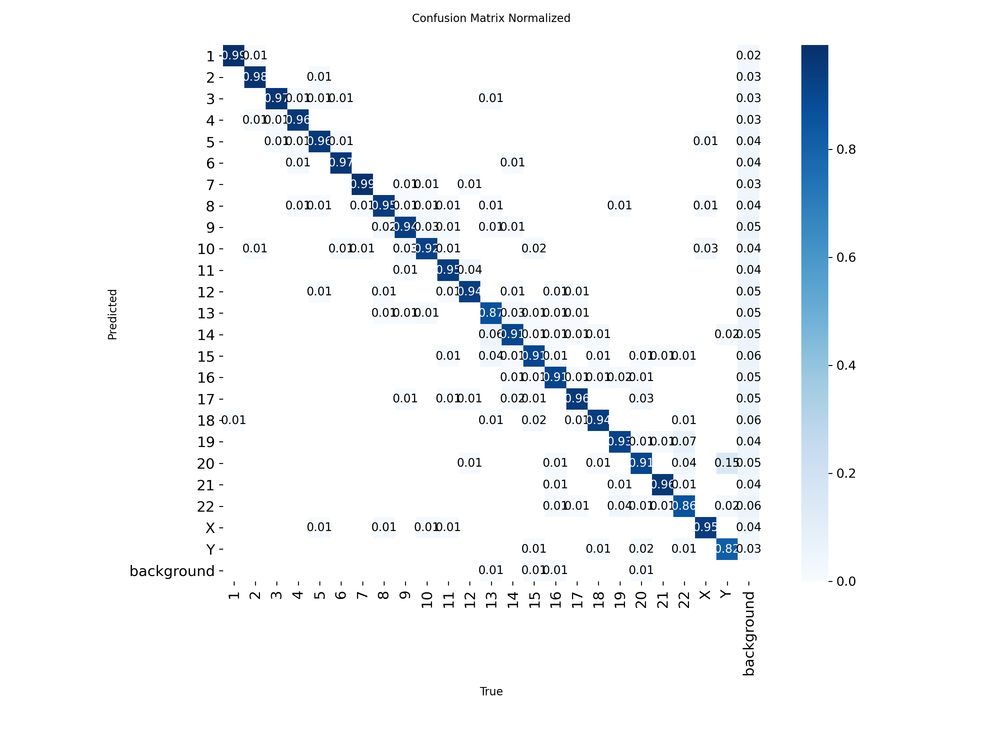

c1 + lienzos | test_completo
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6189.7±2001.0 MB/s, size: 101.7 KB)
val: Scanning /content/data/chromosome1_seg/labels/test... 1398 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1398/1398 1.2Kit/s 1.2s
val: /content/data/chromosome1_seg/images/test/t54816_1050122.jpg: 1 duplicate labels removed
val: /content/data/chromosome1_seg/images/test/t54816_1051131.jpg: 1 duplicate labels removed
val: /content/data/chromosome1_seg/images/test/t54816_1051533.jpg: 1 duplicate labels removed
val: /content/data/chromosome1_seg/images/test/t54816_1051792.jpg: 1 duplicate labels removed
val: /content/data/chromosome1_seg/images/test/t54816_1053281.jpg: 1 duplicate labels removed
val: /content/data/chromosome1_seg/images/test/t54816_1053503.jpg:

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 + lienzos,test_completo,0.989805,0.987737,0.993692,0.906642,0.952791,0.948517,0.951461,0.732139,1.638781,0.601452,2.56017,0.00133,0.659079


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_ft_lienzos_test_completo/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,chromosome,0.989805,0.987737,0.993692,0.906642
1,máscaras,0,chromosome,0.952791,0.948517,0.951461,0.732139


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_ft_lienzos_test_completo/metricas_por_clase.csv
confusion_matrix_normalized.png


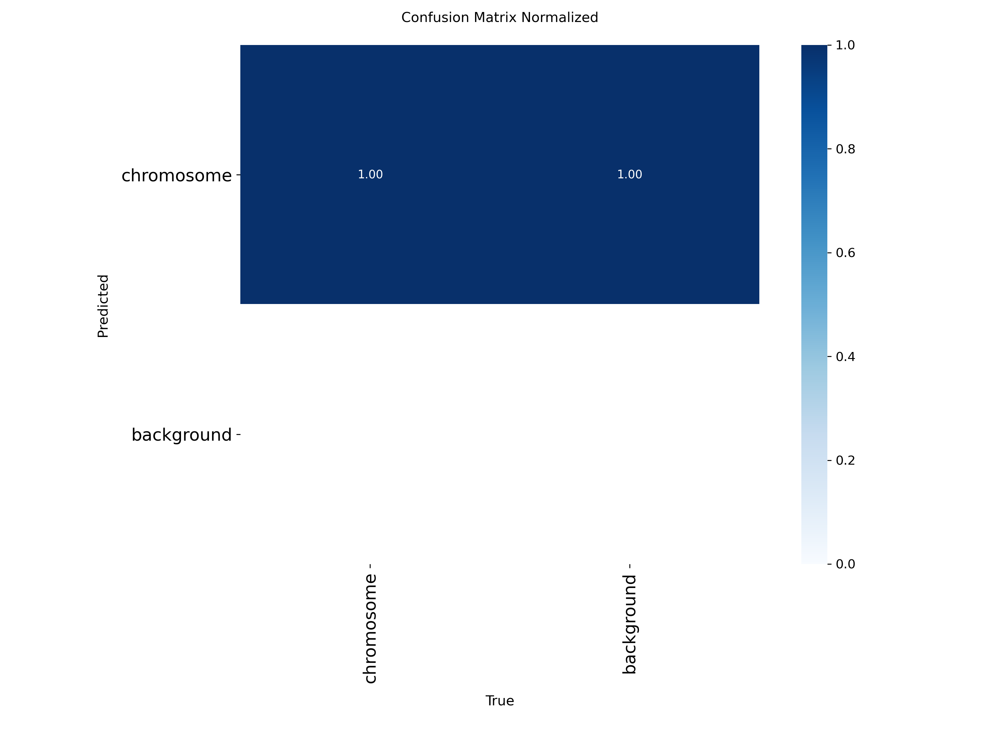

val_batch0_pred.jpg


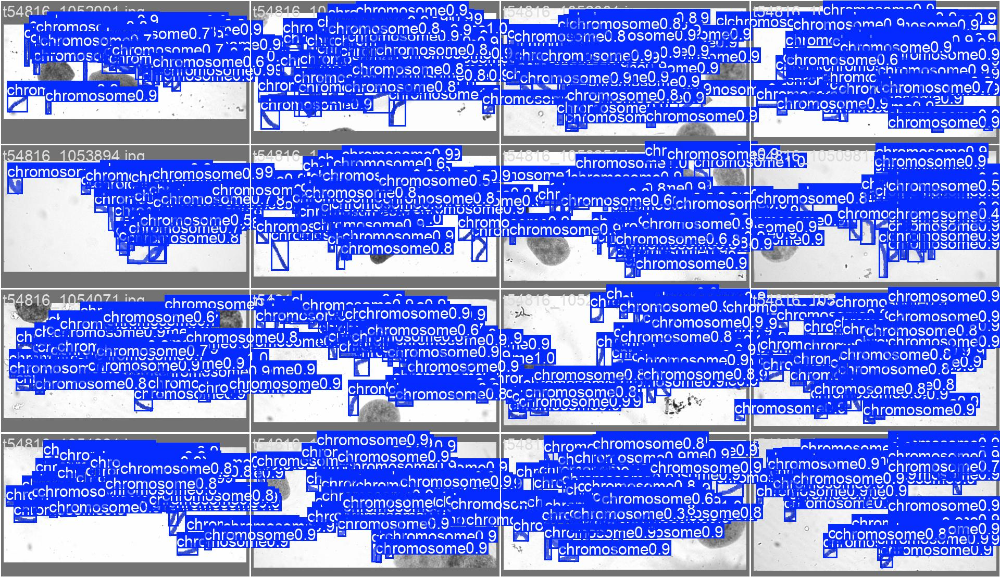

c1 + lienzos | test_autokary
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 13539.0±1174.0 MB/s, size: 2327.1 KB)
val: Scanning /content/data/chromosome1_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 229.9it/s 0.3s
val: New cache created: /content/data/chromosome1_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 3.0s
                   all         75       3212      0.979      0.984      0.993      0.842      0.977      0.983      0.992      0.752
Speed: 3.9ms preprocess, 2.9ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovT

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 + lienzos,test_autokary,0.978801,0.983811,0.992663,0.842024,0.977441,0.982877,0.99175,0.752146,1.59417,3.904312,2.87459,0.000385,2.121637


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_ft_lienzos_test_autokary/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,chromosome,0.978801,0.983811,0.992663,0.842024
1,máscaras,0,chromosome,0.977441,0.982877,0.991750,0.752146


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_ft_lienzos_test_autokary/metricas_por_clase.csv
confusion_matrix_normalized.png


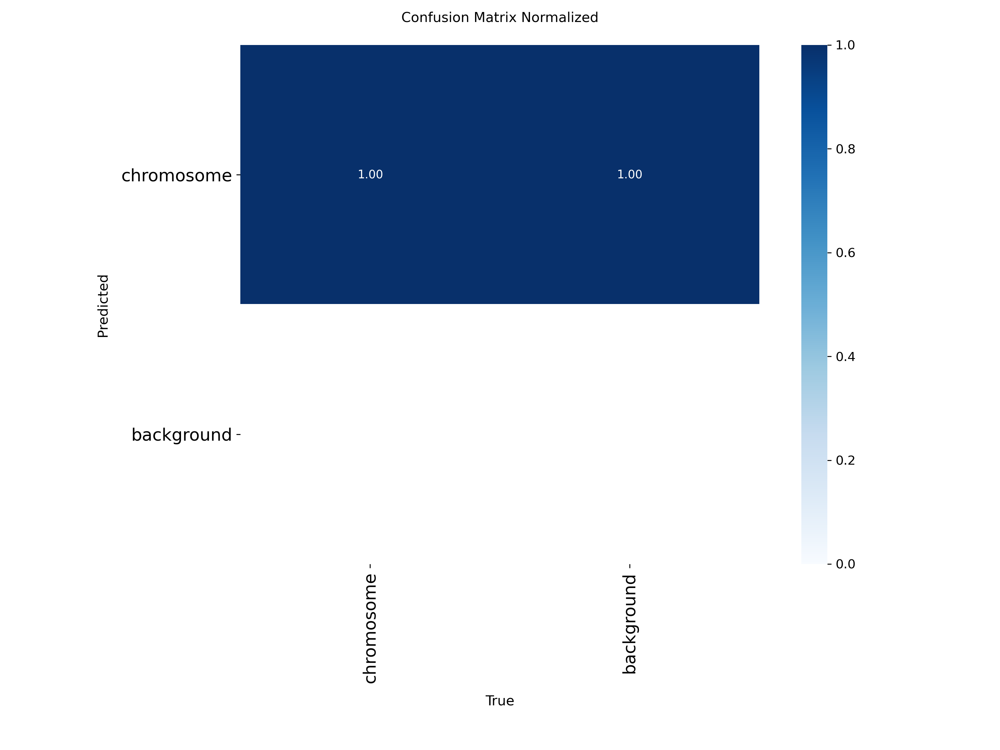

val_batch0_pred.jpg


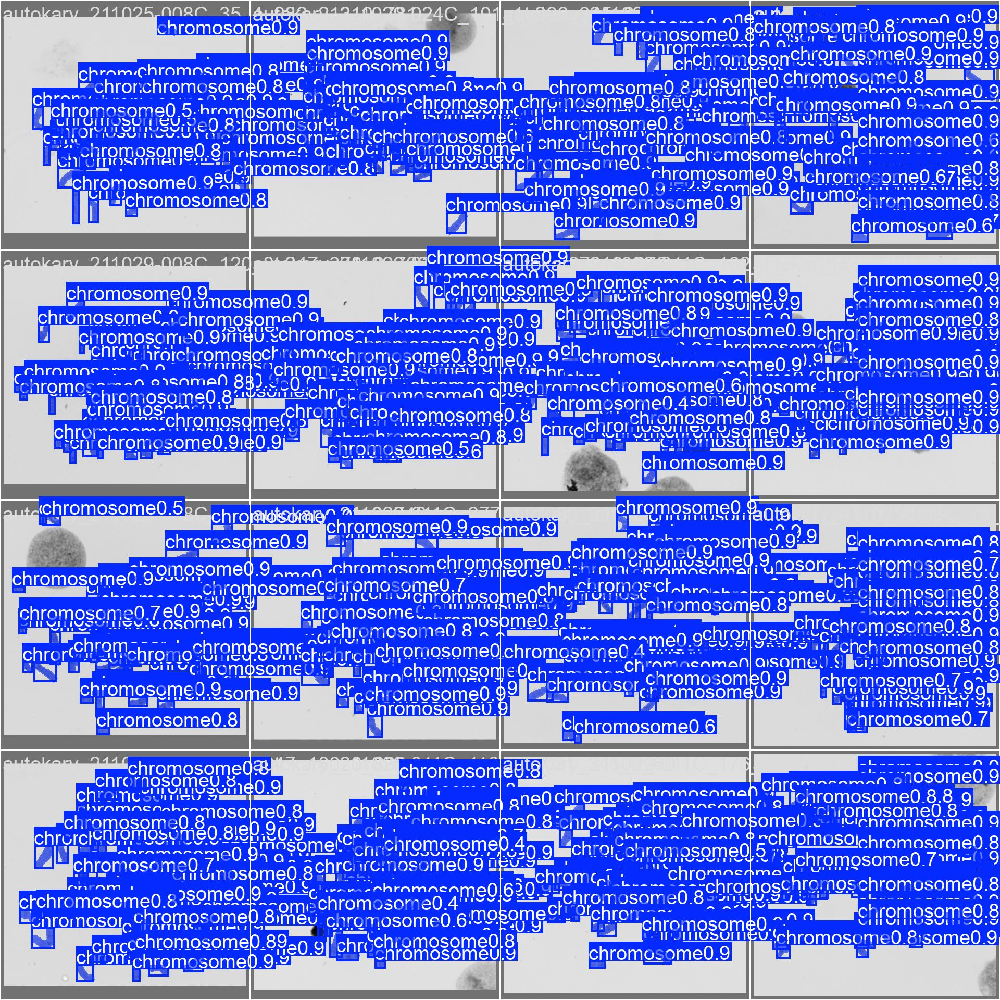

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 (1 clase),test_completo,0.989638,0.989200,0.993777,0.907051,0.953707,0.949251,0.952825,0.737234,1.644284,0.577211,2.803500,0.000557,0.627627
1,c1 (1 clase),test_autokary,0.978092,0.984745,0.992523,0.847024,0.975720,0.983188,0.991921,0.763067,1.610091,3.914586,5.161952,0.000277,1.489364
2,c24 desde c1,test_completo,0.969862,0.954701,0.987316,0.887593,0.938889,0.917445,0.940749,0.728792,1.616385,0.590249,2.384741,0.000716,0.573471
3,c24 desde c1,test_autokary,0.944650,0.914218,0.957209,0.806337,0.944374,0.914500,0.957658,0.731360,1.537697,3.629110,2.803138,0.003665,1.401509
4,c1 + lienzos,test_completo,0.989805,0.987737,0.993692,0.906642,0.952791,0.948517,0.951461,0.732139,1.638781,0.601452,2.560170,0.001330,0.659079
5,c1 + lienzos,test_autokary,0.978801,0.983811,0.992663,0.842024,0.977441,0.982877,0.991750,0.752146,1.594170,3.904312,2.874590,0.000385,2.121637


/content/drive/MyDrive/yolo_runs/resumen_test.csv


,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 (1 clase),test_completo,0.989638,0.989200,0.993777,0.907051,0.953707,0.949251,0.952825,0.737234,1.644284,0.577211,2.803500,0.000557,0.627627
1,c1 (1 clase),test_autokary,0.978092,0.984745,0.992523,0.847024,0.975720,0.983188,0.991921,0.763067,1.610091,3.914586,5.161952,0.000277,1.489364
2,c24 desde c1,test_completo,0.969862,0.954701,0.987316,0.887593,0.938889,0.917445,0.940749,0.728792,1.616385,0.590249,2.384741,0.000716,0.573471
3,c24 desde c1,test_autokary,0.944650,0.914218,0.957209,0.806337,0.944374,0.914500,0.957658,0.731360,1.537697,3.629110,2.803138,0.003665,1.401509
4,c1 + lienzos,test_completo,0.989805,0.987737,0.993692,0.906642,0.952791,0.948517,0.951461,0.732139,1.638781,0.601452,2.560170,0.001330,0.659079
5,c1 + lienzos,test_autokary,0.978801,0.983811,0.992663,0.842024,0.977441,0.982877,0.991750,0.752146,1.594170,3.904312,2.874590,0.000385,2.121637


In [ ]:
MODELOS_DISPONIBLES = [label for label in RUNS if os.path.isfile(weights(label))]
if not MODELOS_DISPONIBLES:
    raise FileNotFoundError(f'No hay pesos best.pt en {RUNS_DIR}.')
display(pd.DataFrame([
    {'modelo': label, 'best.pt': weights(label), 'disponible': label in MODELOS_DISPONIBLES}
    for label in RUNS
]))


def guardar_tabla(rows, path):
    table = pd.DataFrame(rows)
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(path, index=False)
    display(table)
    print(path)
    return table


def evaluar(label, data_yaml, name, **kwargs):
    print(f'{label} | {name}')
    model = YOLO(weights(label))
    metrics = model.val(
        data=data_yaml, split='test', imgsz=IMGSZ, batch=BATCH,
        plots=True, verbose=True, project=RUNS_DIR,
        name=f'{RUNS[label]}_{name}', exist_ok=True, **kwargs,
    )
    folder = Path(metrics.save_dir)
    global_row = {'modelo': label, 'evaluación': name, **metrics.results_dict}
    global_row.update({f'tiempo_{k}_ms': v for k, v in metrics.speed.items()})
    guardar_tabla([global_row], folder / 'metricas_globales.csv')

    class_rows = []
    for tipo, metric in [('cajas', metrics.box)] + ([('máscaras', metrics.seg)] if SEG else []):
        for i, class_id in enumerate(metric.ap_class_index):
            p, r, ap50, ap = metric.class_result(i)
            class_rows.append({
                'tipo': tipo, 'clase_id': int(class_id),
                'clase': 'cromosoma' if kwargs.get('single_cls') else model.names[int(class_id)],
                'precision': p, 'recall': r, 'mAP50': ap50, 'mAP50-95': ap,
            })
    guardar_tabla(class_rows, folder / 'metricas_por_clase.csv')

    cm = getattr(metrics, 'confusion_matrix', None)
    if cm is not None:
        np.savetxt(folder / 'matriz_confusion.csv', cm.matrix, delimiter=',')
    mostrar_figuras(folder)
    return global_row


TESTS = {}
for label in MODELOS_DISPONIBLES:
    is_c24 = label.startswith('c24')
    data_dir, data_yaml = (C24_DIR, C24_YAML) if is_c24 else (C1_DIR, C1_YAML)
    prefix = 'c24' if is_c24 else 'c1'
    autokary = list_images(f'{data_dir}/images/test', 'autokary_')
    TESTS[label] = {
        'test_completo': data_yaml,
        'test_autokary': subset_yaml(data_yaml, f'{prefix}_autokary', autokary),
    }

test_rows = []
for label, subsets in TESTS.items():
    for name, data_yaml in subsets.items():
        test_rows.append(evaluar(label, data_yaml, name))
guardar_tabla(test_rows, Path(RUNS_DIR) / 'resumen_test.csv')

### Matrices de confusión de 24 clases con confianza 0.1

c24 desde c1 | cm_autokary_conf01
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 12611.2±1797.8 MB/s, size: 2377.8 KB)
val: Scanning /content/data/chromosome24_seg/labels/test.cache... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 39.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.6it/s 2.5s
                   all         75       3208      0.946      0.917      0.921      0.779      0.947      0.917      0.922      0.708
                     1         74        147      0.991      0.986      0.995      0.924      0.985       0.98      0.995      0.787
                     2         75        140      0.986      0.978      0.971      0.903    

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,cm_autokary_conf01,0.946399,0.917142,0.921077,0.778984,0.946624,0.917486,0.921602,0.707521,1.486505,3.682909,2.939073,0.004142,0.952147


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_cm_autokary_conf01/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,1,0.991411,0.986395,0.994865,0.923746
1,cajas,1,2,0.985610,0.978451,0.971024,0.902825
2,cajas,2,3,0.953995,0.964029,0.966594,0.879994
3,cajas,3,4,0.971574,0.958333,0.953137,0.885334
4,cajas,4,5,0.971188,0.958904,0.957593,0.872229
5,cajas,5,6,0.989171,0.965035,0.965000,0.871579
6,cajas,6,7,0.985302,0.972222,0.984442,0.873882
7,cajas,7,8,0.942925,0.944059,0.933976,0.828059
8,cajas,8,9,0.941627,0.896177,0.916587,0.798940
9,cajas,9,10,0.934665,0.896552,0.909327,0.813257


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_cm_autokary_conf01/metricas_por_clase.csv
confusion_matrix_normalized.png


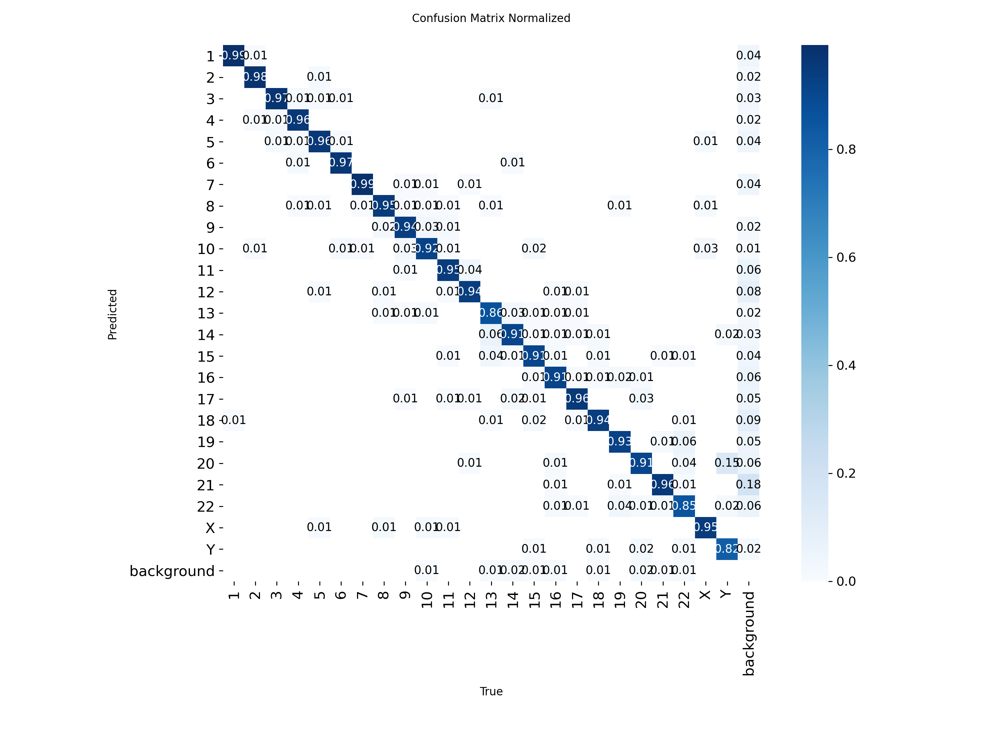

val_batch0_pred.jpg


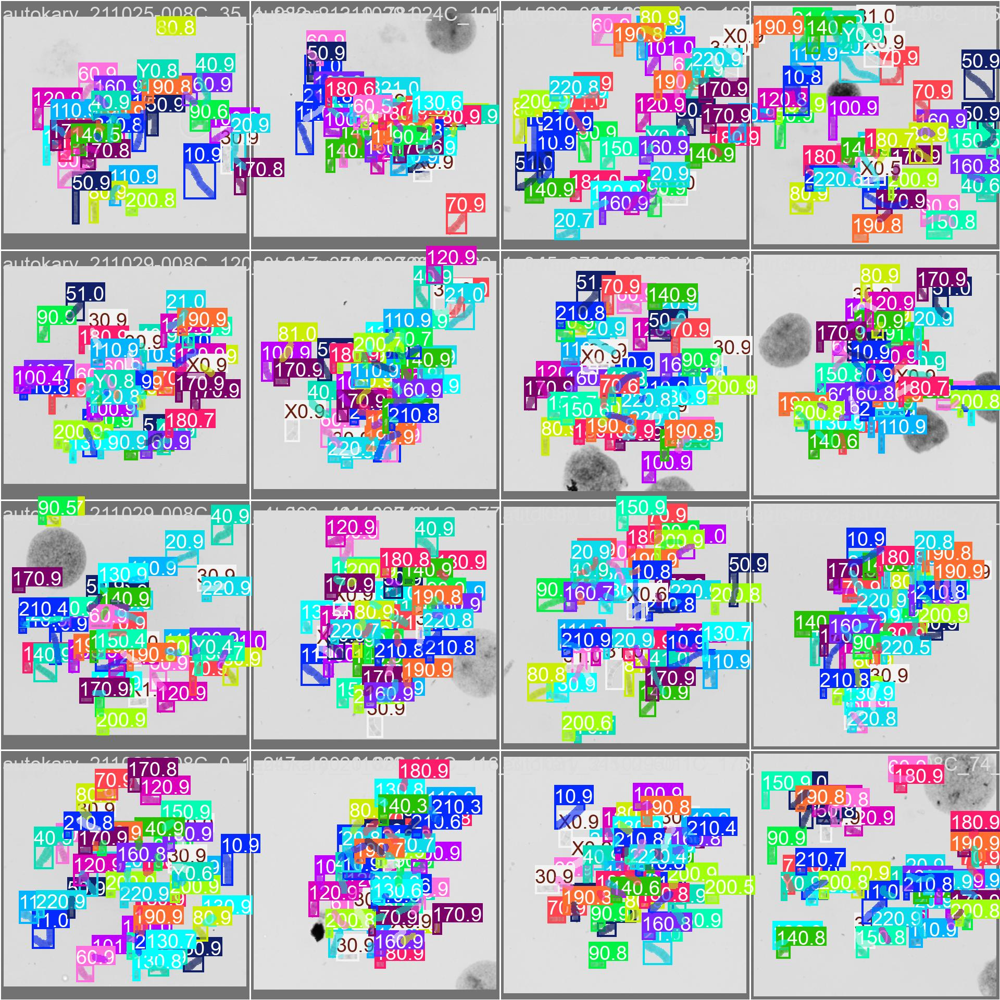

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,cm_autokary_conf01,0.946399,0.917142,0.921077,0.778984,0.946624,0.917486,0.921602,0.707521,1.486505,3.682909,2.939073,0.004142,0.952147


/content/drive/MyDrive/yolo_runs/resumen_cm_conf01.csv


,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,cm_autokary_conf01,0.946399,0.917142,0.921077,0.778984,0.946624,0.917486,0.921602,0.707521,1.486505,3.682909,2.939073,0.004142,0.952147


In [ ]:
cm_rows = []
for label in MODELOS_DISPONIBLES:
    if label.startswith('c24'):
        cm_rows.append(evaluar(
            label, TESTS[label]['test_autokary'], 'cm_autokary_conf01',
            conf=0.1, agnostic_nms=True,
        ))
guardar_tabla(cm_rows, Path(RUNS_DIR) / 'resumen_cm_conf01.csv')

### Segmentación por dataset, ignorando la clase

AutoKary usa máscaras dibujadas a mano; 54816 usa máscaras generadas con SAM.
Solo c1 y sus ajustes finos se entrenaron con los recortes de solapamientos.

c1 (1 clase) | seg_AutoKary2022
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 13501.3±2939.5 MB/s, size: 2417.4 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 336.4it/s 0.2s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 2.8s
                   all         75       3208      0.977      0.985      0.992      0.847      0.975      0.983      0.992      0.763
Speed: 4.3ms preprocess, 3.6ms inference, 0.0ms loss, 1.1ms postprocess per image
Results

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 (1 clase),seg_AutoKary2022,0.977164,0.985037,0.992272,0.847457,0.974793,0.983479,0.991705,0.763374,1.610831,4.282379,3.642639,0.000302,1.084841


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_seg_AutoKary2022/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,cromosoma,0.977164,0.985037,0.992272,0.847457
1,máscaras,0,cromosoma,0.974793,0.983479,0.991705,0.763374


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_seg_AutoKary2022/metricas_por_clase.csv
confusion_matrix_normalized.png


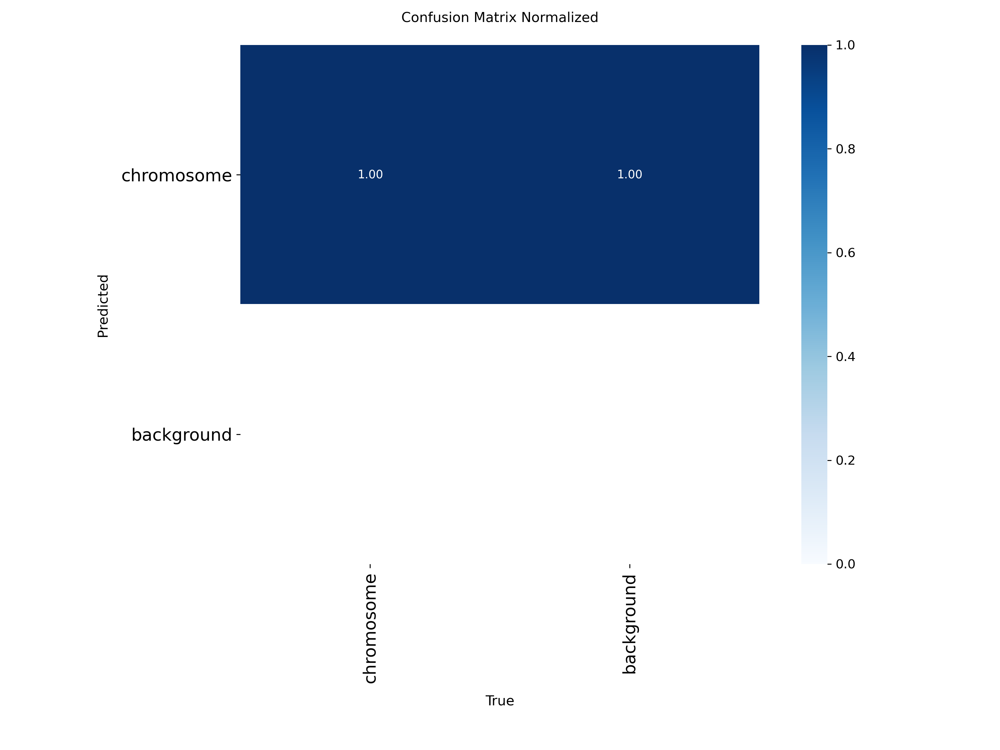

val_batch0_pred.jpg


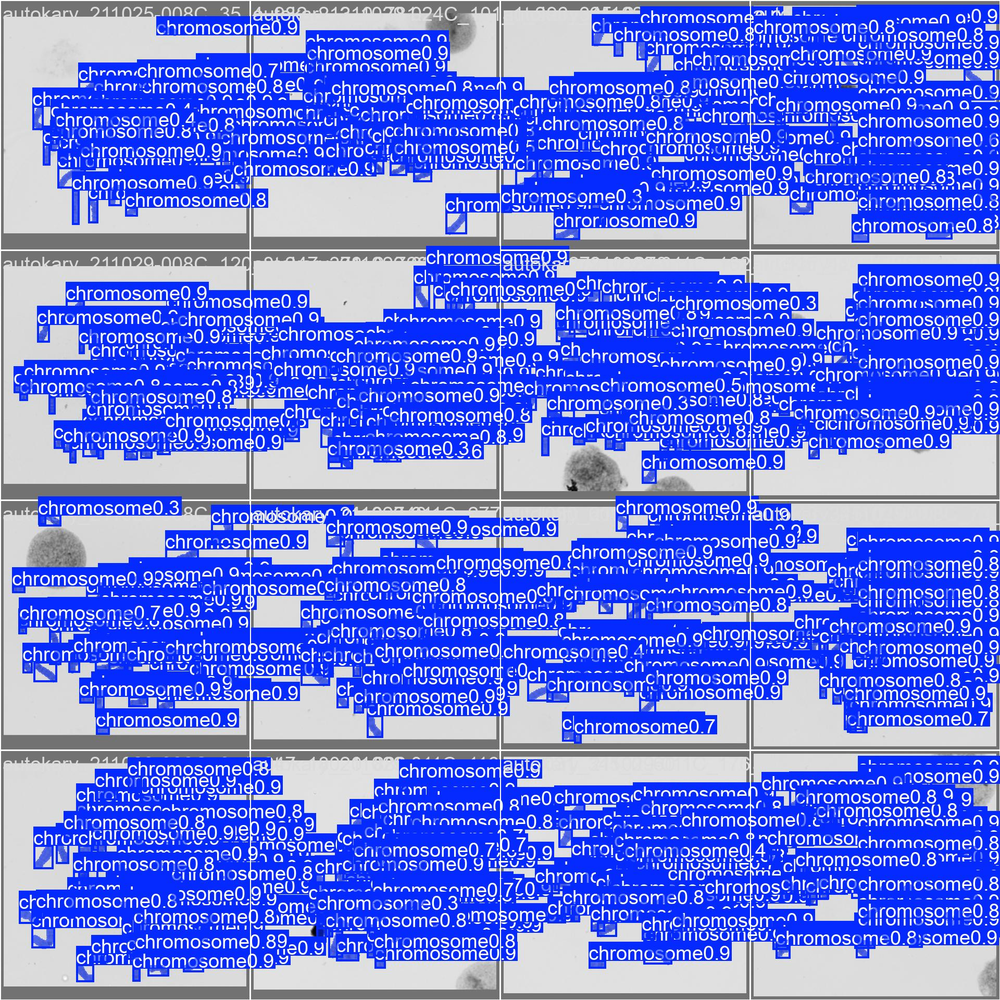

c1 (1 clase) | seg_54816
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5833.6±1138.7 MB/s, size: 106.9 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 1250 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1250/1250 1.3Kit/s 1.0s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 53/53 5.5it/s 9.6s
                   all       1250      57484      0.991      0.989      0.994       0.91      0.952      0.947      0.952      0.736
Speed: 0.6ms preprocess, 2.5ms inference, 0.0ms loss, 0.7ms postprocess per image
Results s

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 (1 clase),seg_54816,0.99056,0.98934,0.993861,0.910482,0.952454,0.947342,0.952191,0.735857,1.646339,0.611449,2.542285,0.000204,0.692363


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_seg_54816/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,cromosoma,0.990560,0.989340,0.993861,0.910482
1,máscaras,0,cromosoma,0.952454,0.947342,0.952191,0.735857


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_seg_54816/metricas_por_clase.csv
confusion_matrix_normalized.png


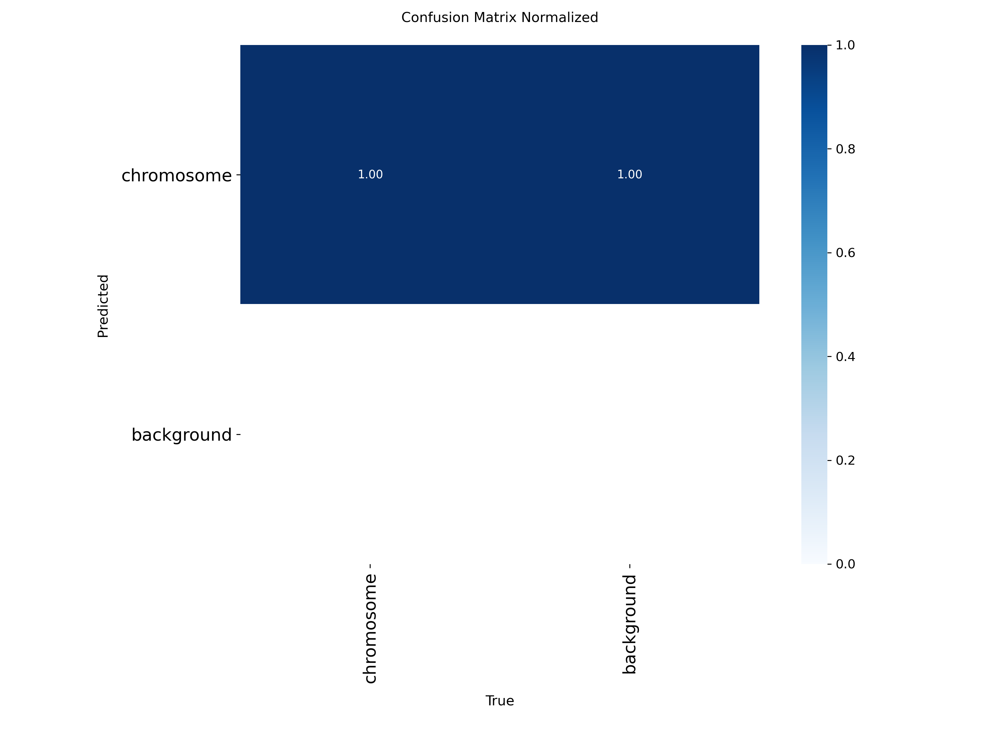

val_batch0_pred.jpg


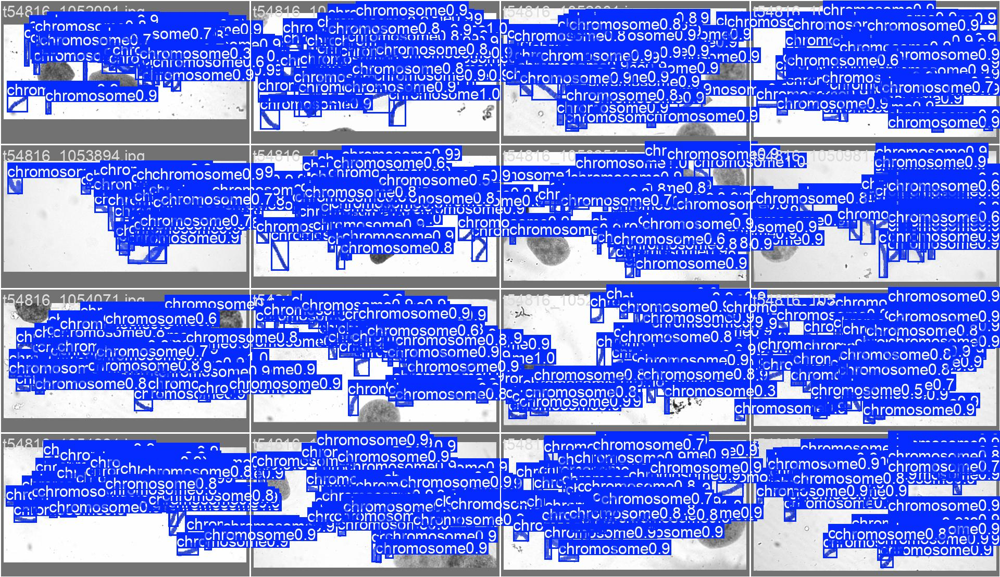

c1 (1 clase) | seg_Solapamientos
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1638.4±589.7 MB/s, size: 14.3 KB)
val: Scanning /content/data/chromosome1_seg/labels/test... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 2.3Kit/s 0.0s
val: New cache created: /content/data/chromosome1_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.2it/s 1.3s
                   all         73        146       0.91      0.959      0.962      0.718      0.895      0.938      0.945      0.564
Speed: 3.8ms preprocess, 3.4ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTu

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 (1 clase),seg_Solapamientos,0.909861,0.958904,0.962226,0.717836,0.894888,0.938356,0.945169,0.563805,1.281641,3.787775,3.352808,0.000304,0.609756


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_seg_Solapamientos/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,cromosoma,0.909861,0.958904,0.962226,0.717836
1,máscaras,0,cromosoma,0.894888,0.938356,0.945169,0.563805


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_seg_Solapamientos/metricas_por_clase.csv
confusion_matrix_normalized.png


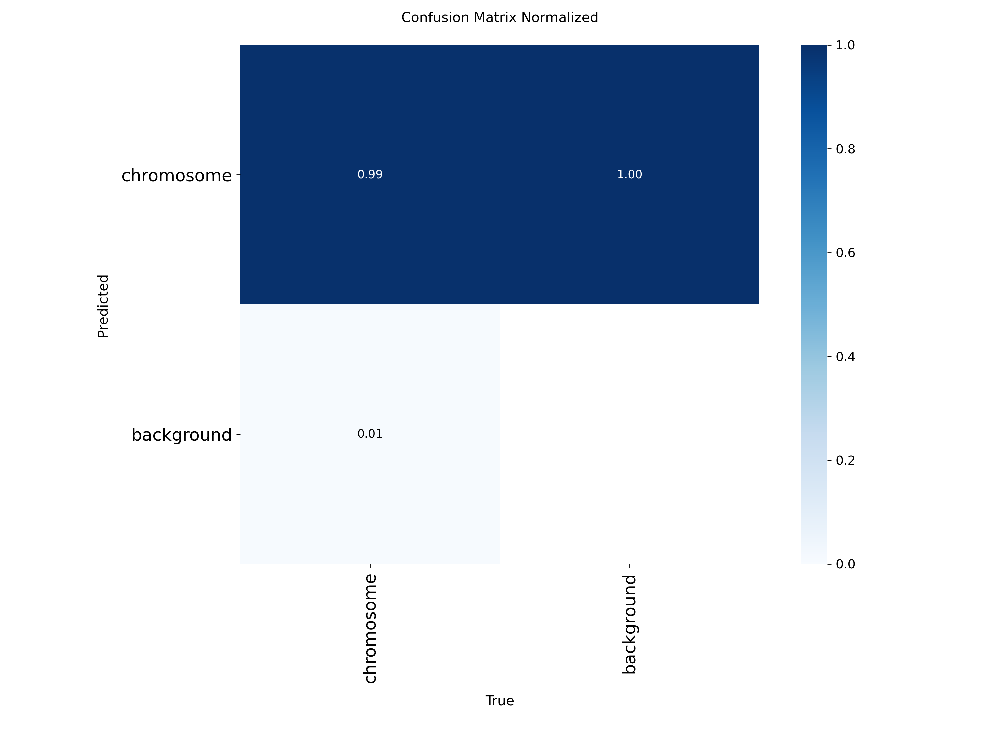

val_batch0_pred.jpg


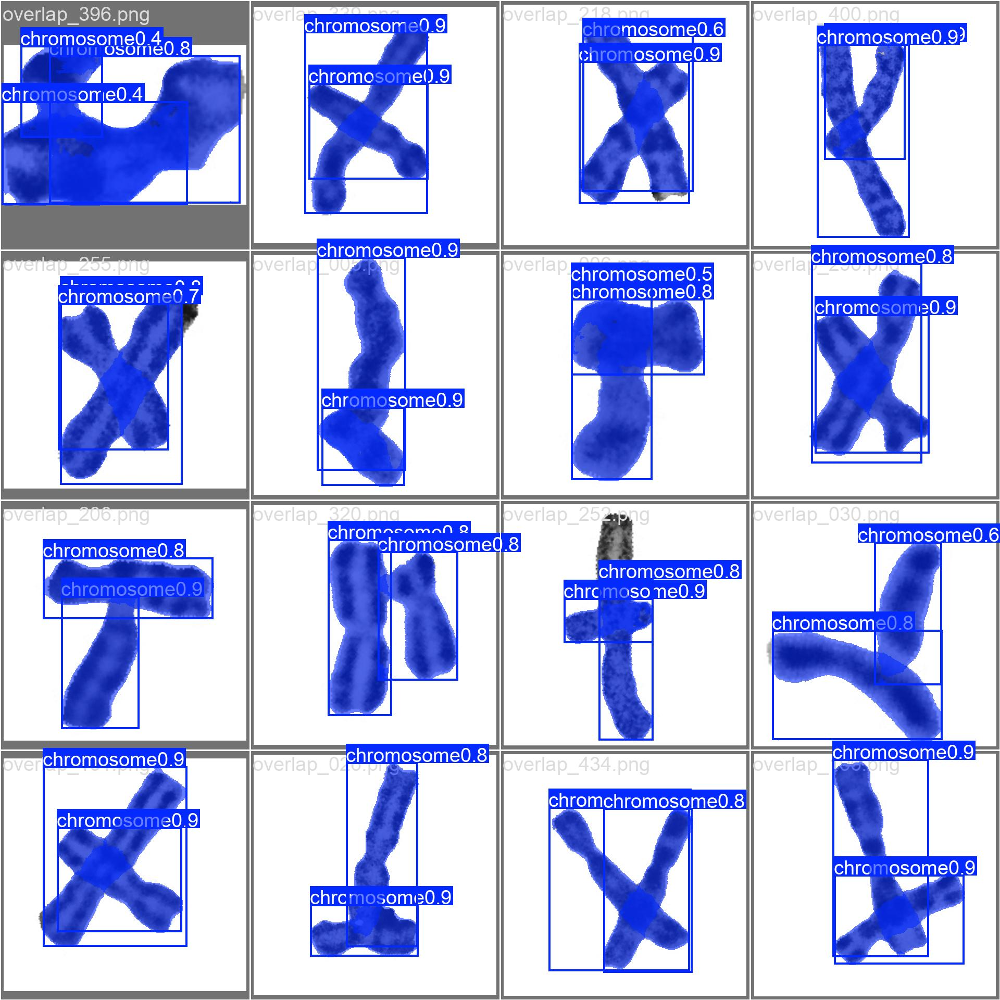

c24 desde c1 | seg_AutoKary2022
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 11635.4±2231.1 MB/s, size: 2420.7 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 350.6it/s 0.2s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.7it/s 2.4s
                   all         75       3208      0.982      0.986      0.993       0.84      0.981      0.986      0.993       0.76
                     1         75       3208      0.982      0.986      0.993       0.84      0.981      0.986      0.993       0.76
Speed: 4.0ms preprocess, 2.

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,seg_AutoKary2022,0.981695,0.986321,0.993301,0.839906,0.981074,0.985697,0.993192,0.760053,1.599959,4.041612,2.826598,0.000272,0.966308


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_seg_AutoKary2022/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,cromosoma,0.981695,0.986321,0.993301,0.839906
1,máscaras,0,cromosoma,0.981074,0.985697,0.993192,0.760053


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_seg_AutoKary2022/metricas_por_clase.csv
confusion_matrix_normalized.png


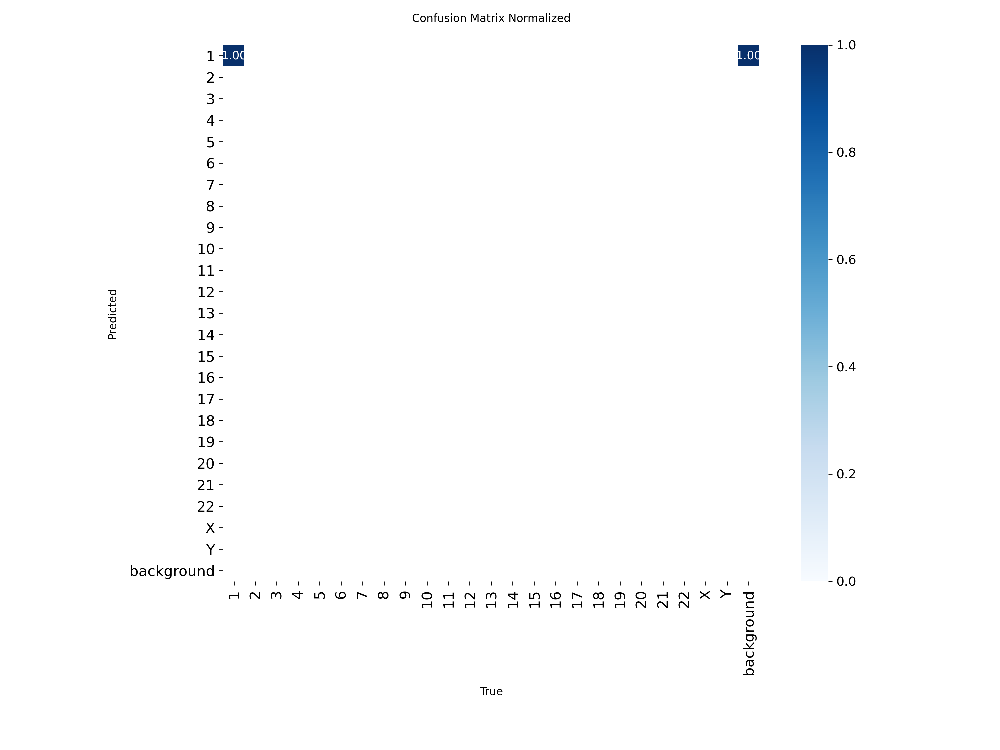

val_batch0_pred.jpg


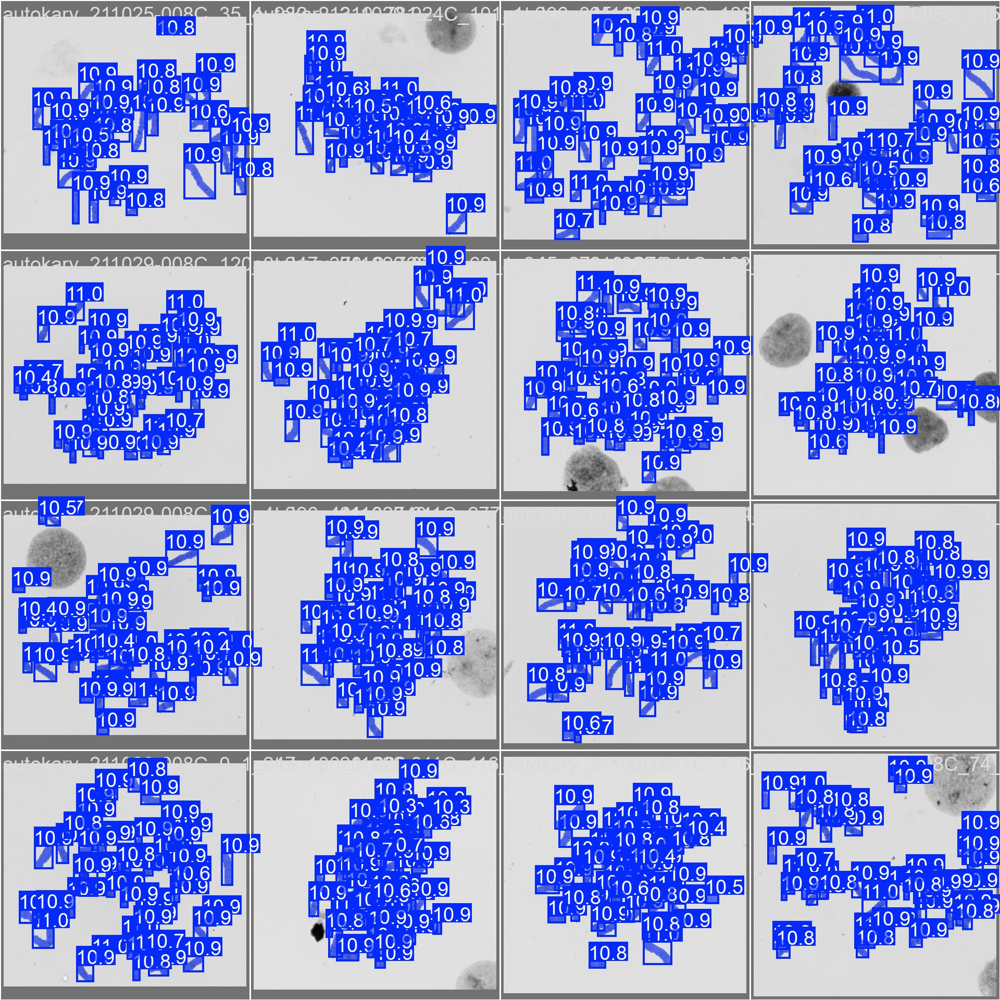

c24 desde c1 | seg_54816
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6290.8±788.3 MB/s, size: 89.6 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 1250 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1250/1250 1.3Kit/s 1.0s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 53/53 6.8it/s 7.8s
                   all       1250      57484      0.991       0.99      0.994        0.9      0.953      0.947      0.943      0.727
                     1       1250      57484      0.991       0.99      0.994        0.9      0.953      0.947      0.943      0.727
Speed: 0.6ms preprocess, 2.3ms 

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,seg_54816,0.990529,0.989695,0.994386,0.899674,0.952717,0.946959,0.943296,0.726643,1.626316,0.621974,2.342389,0.000193,0.482699


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_seg_54816/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,cromosoma,0.990529,0.989695,0.994386,0.899674
1,máscaras,0,cromosoma,0.952717,0.946959,0.943296,0.726643


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_seg_54816/metricas_por_clase.csv
confusion_matrix_normalized.png


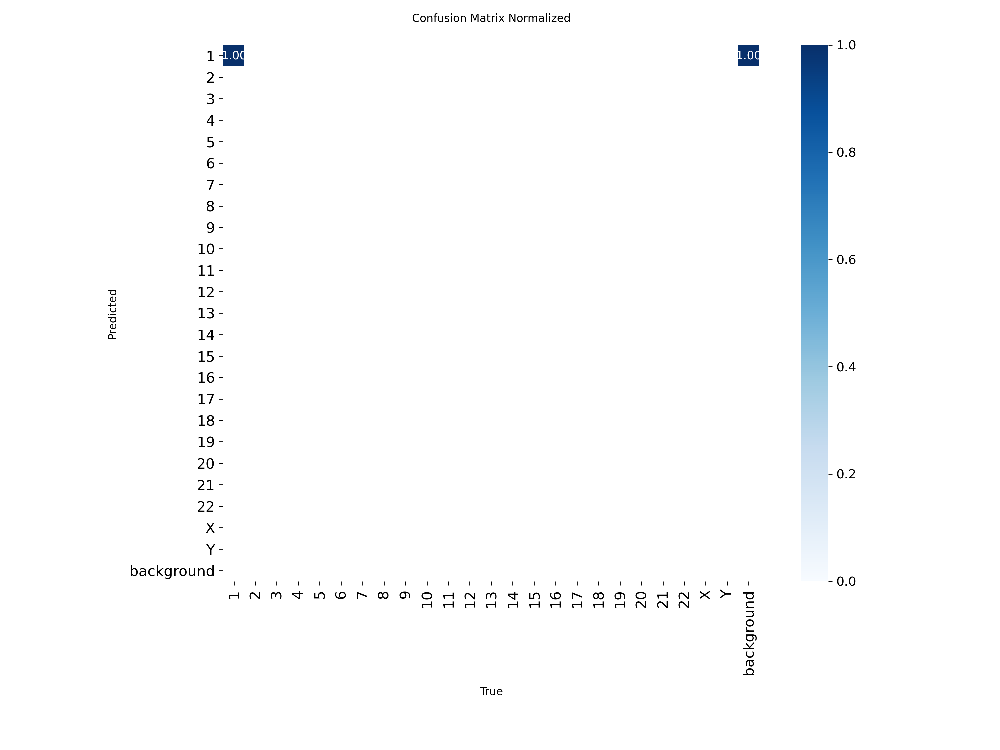

val_batch0_pred.jpg


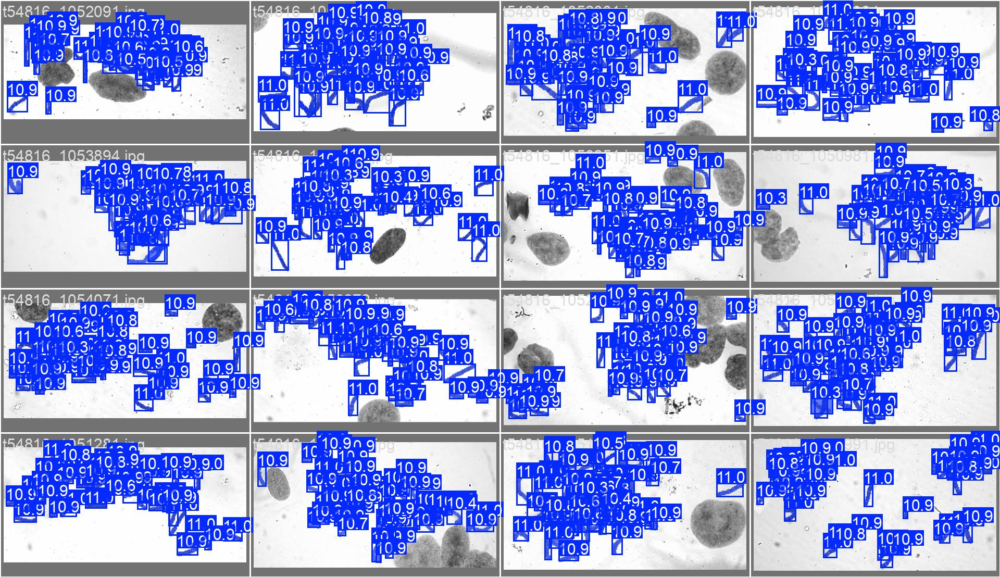

c24 desde c1 | seg_Solapamientos
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,076,104 parameters, 0 gradients, 33.0 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1610.0±425.8 MB/s, size: 16.3 KB)
val: Scanning /content/data/chromosome1_seg/labels/test.cache... 73 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 73/73 27.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 3.2it/s 1.2s
                   all         73        146      0.691      0.751      0.757      0.402       0.67      0.637       0.66      0.287
                     1         73        146      0.691      0.751      0.757      0.402       0.67      0.637       0.66      0.287
Speed: 3.8ms preprocess, 2.8ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c24 desde c1,seg_Solapamientos,0.691048,0.750699,0.757467,0.40182,0.670224,0.636986,0.659933,0.286524,0.688344,3.816986,2.810292,0.000197,0.673687


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_seg_Solapamientos/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,cromosoma,0.691048,0.750699,0.757467,0.401820
1,máscaras,0,cromosoma,0.670224,0.636986,0.659933,0.286524


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome24_yolo11s-seg_1024_desde_c1_seg_Solapamientos/metricas_por_clase.csv
confusion_matrix_normalized.png


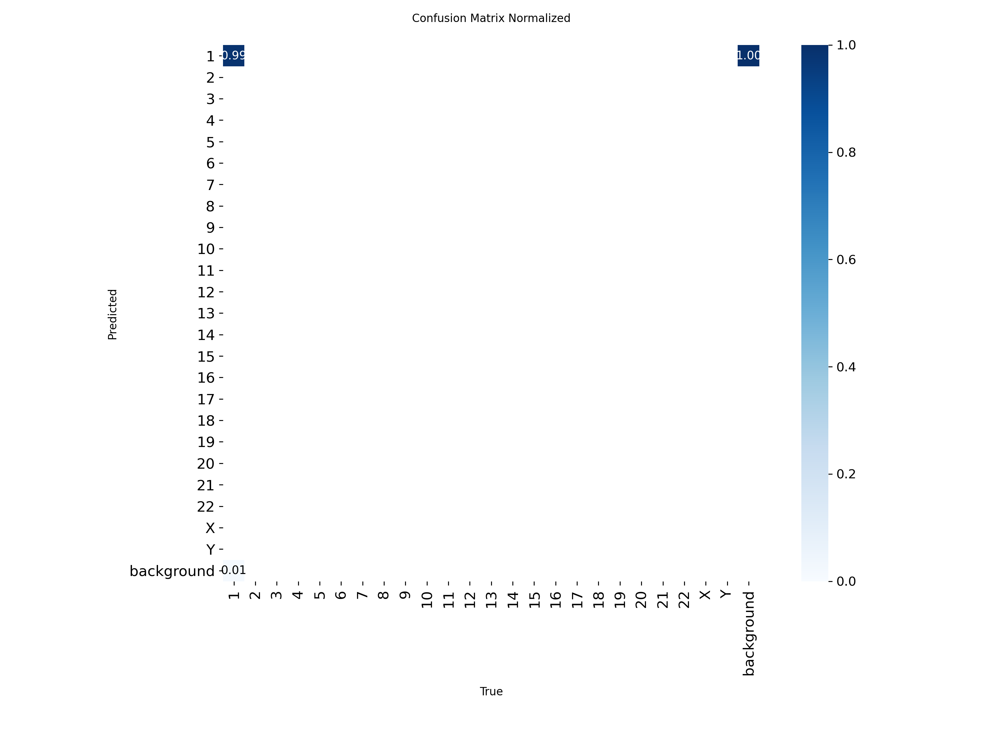

val_batch0_pred.jpg


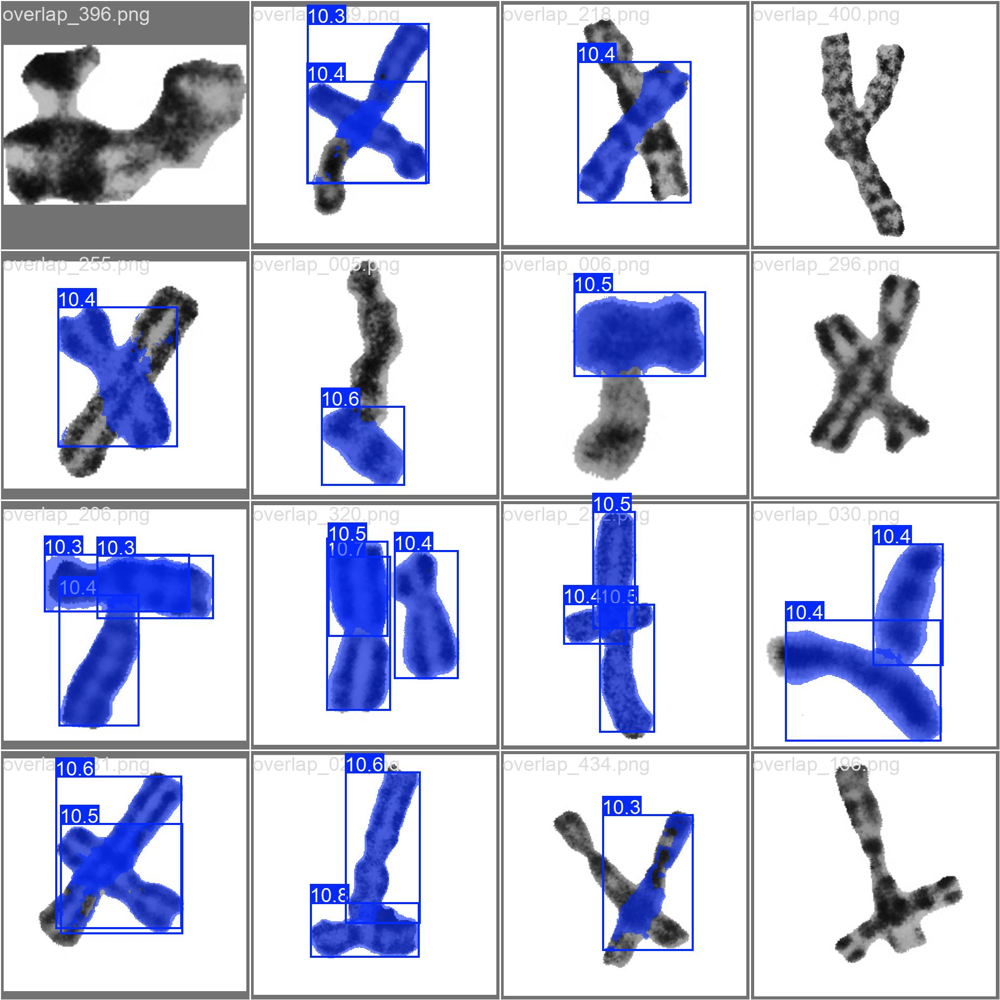

c1 + lienzos | seg_AutoKary2022
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 16355.7±4024.5 MB/s, size: 2392.4 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 342.2it/s 0.2s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 3.0s
                   all         75       3208      0.978      0.984      0.992      0.843      0.977      0.983      0.992      0.753
Speed: 4.4ms preprocess, 3.1ms inference, 0.0ms loss, 1.7ms postprocess per image
Results

,modelo,evaluación,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M),fitness,tiempo_preprocess_ms,tiempo_inference_ms,tiempo_loss_ms,tiempo_postprocess_ms
0,c1 + lienzos,seg_AutoKary2022,0.977872,0.984102,0.992398,0.842522,0.976943,0.983167,0.991501,0.753169,1.595691,4.405067,3.079332,0.00033,1.711196


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_ft_lienzos_seg_AutoKary2022/metricas_globales.csv


,tipo,clase_id,clase,precision,recall,mAP50,mAP50-95
0,cajas,0,cromosoma,0.977872,0.984102,0.992398,0.842522
1,máscaras,0,cromosoma,0.976943,0.983167,0.991501,0.753169


/content/drive/.shortcut-targets-by-id/1c9m8hX8C8UKQ4jcD7AOSJQTovTuFQFvU/yolo_runs/chromosome1_yolo11s-seg_1024_ft_lienzos_seg_AutoKary2022/metricas_por_clase.csv
confusion_matrix_normalized.png


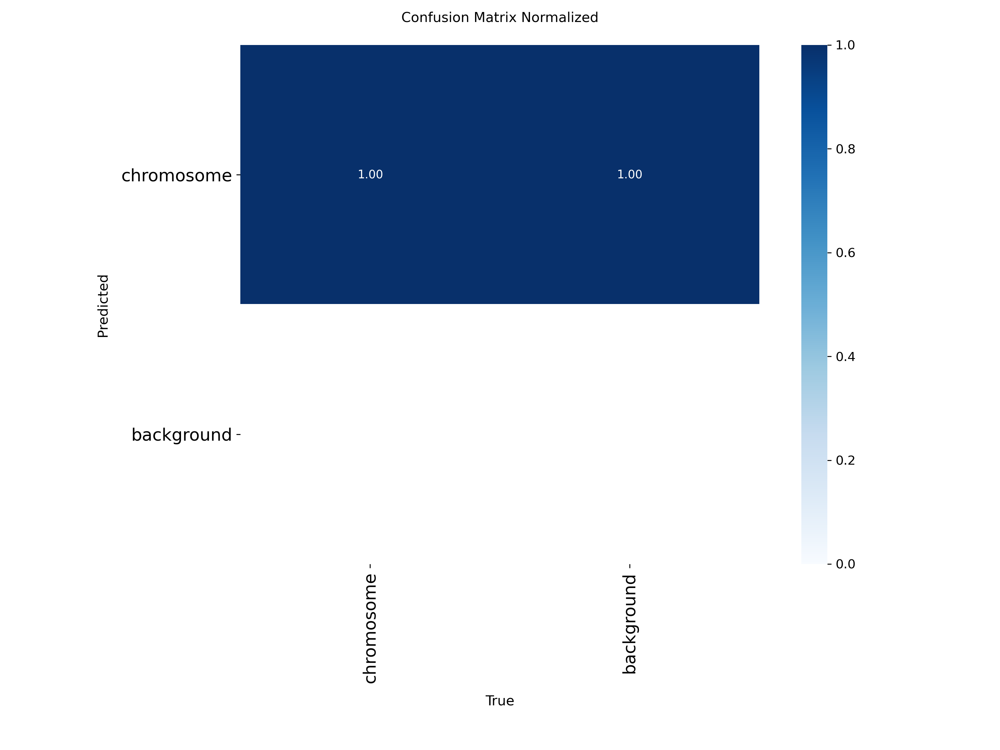

val_batch0_pred.jpg


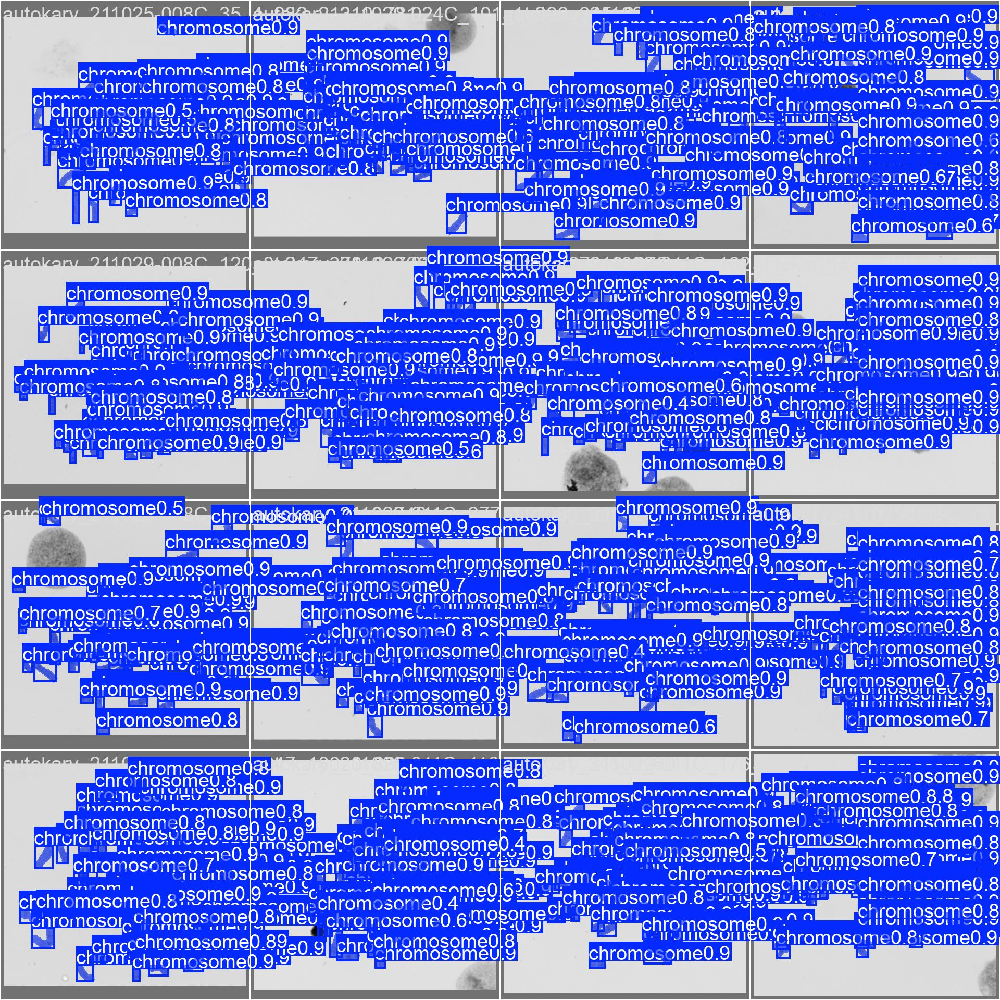

c1 + lienzos | seg_54816
Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA RTX PRO 6000 Blackwell Server Edition, 97250MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6531.7±1475.8 MB/s, size: 77.6 KB)
val: Scanning /content/data/chromosome24_seg/labels/test... 1250 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1250/1250 1.3Kit/s 1.0s
val: New cache created: /content/data/chromosome24_seg/labels/test.cache
WARNING ⚠️ Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 11% ━─────────── 6/53 1.5it/s 3.8s<31.7s


KeyboardInterrupt: 

In [ ]:
if SEG:
    SEG_SETS = {
        'AutoKary2022': subset_yaml(C24_YAML, 'seg_autokary', list_images(f'{C24_DIR}/images/test', 'autokary_')),
        '54816': subset_yaml(C24_YAML, 'seg_54816', list_images(f'{C24_DIR}/images/test', 't54816')),
        'Solapamientos': subset_yaml(C1_YAML, 'seg_overlap', list_images(f'{C1_DIR}/images/test', 'overlap_')),
    }
    seg_rows = []
    for label in MODELOS_DISPONIBLES:
        for dataset, data_yaml in SEG_SETS.items():
            seg_rows.append(evaluar(label, data_yaml, f'seg_{dataset}', single_cls=True))
    guardar_tabla(seg_rows, Path(RUNS_DIR) / 'resumen_segmentacion.csv')

## 7. Solapamientos

Se conservan las mediciones de IoU de los cromosomas y de su zona compartida.
Los resultados se muestran en tablas y se guardan en CSV.

In [ ]:
def read_polygons(label_path, W, H):
    """[(clase, polígono en píxeles)] de un .txt de YOLO."""
    out = []
    with open(label_path) as fh:
        for line in fh:
            v = line.split()
            if v:
                out.append((int(v[0]), np.array(v[1:], float).reshape(-1, 2) * [W, H]))
    return out

def polygon_mask(p, W, H):
    m = PILImage.new('1', (W, H), 0)
    ImageDraw.Draw(m).polygon([tuple(q) for q in p], fill=1)
    return np.asarray(m)

def mask_box(m):
    ys, xs = np.flatnonzero(m.any(1)), np.flatnonzero(m.any(0))
    return (xs[0], ys[0], xs[-1] + 1, ys[-1] + 1) if len(xs) else (0, 0, 0, 0)

def boxes_touch(a, b):
    return a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]

def union_box(*boxes):
    boxes = [b for b in boxes if b[2] > b[0]]
    return min(b[0] for b in boxes), min(b[1] for b in boxes), max(b[2] for b in boxes), max(b[3] for b in boxes)

def mask_iou(a, b):
    union = (a | b).sum()
    return (a & b).sum() / union if union else 0.0

def iou_in(a, b, box):
    x0, y0, x1, y1 = box
    return mask_iou(a[y0:y1, x0:x1], b[y0:y1, x0:x1])

def predict_masks(model, path, conf, agnostic=True):
    """Máscaras binarias (H, W) de la predicción. agnostic=True: una máscara por cromosoma aunque el modelo dude entre
    dos clases (sin esto, con 24 clases pueden quedar una "21" y una "22" sobre el mismo cromosoma)."""
    r = model.predict(path, imgsz=IMGSZ, conf=conf, agnostic_nms=agnostic, retina_masks=True, verbose=False)[0]
    if r.masks is None:
        return []
    H, W = r.orig_shape
    return [m if m.shape == (H, W) else np.asarray(PILImage.fromarray(m).resize((W, H), PILImage.NEAREST))
            for m in r.masks.data.cpu().numpy() > 0.5]

def evaluate_crop(gt, pred, min_cross):
    """Recorte de solapamiento: empareja cada cromosoma real con la máscara predicha que más se le parece y mide
    el IoU de cada cromosoma y el de la zona de cruce."""
    ious = np.array([[mask_iou(g, p) for p in pred] for g in gt]).reshape(len(gt), len(pred))
    match = {}
    for v, j, i in sorted(((ious[j, i], j, i) for j in range(len(gt)) for i in range(len(pred))), reverse=True):
        if v > 0 and j not in match and i not in match.values():
            match[j] = i
    gt_cross = np.sum(gt, 0) >= 2
    pred_cross = np.sum(pred, 0) >= 2 if len(pred) >= 2 else np.zeros_like(gt_cross)
    share = gt_cross.sum() / min(g.sum() for g in gt)
    return dict(pred=pred, match=match, chrom=[ious[j, match[j]] if j in match else 0.0 for j in range(len(gt))],
                pred_cross=pred_cross, share=share, cross=mask_iou(gt_cross, pred_cross) if share >= min_cross else None)

In [ ]:
def overlap_benchmark(labels, mode='recortes', conf=0.25, min_cross=0.02, tag=''):
    """Compara modelos en los recortes de solapamientos de test.
    mode='recortes': cada recorte solo, que Ultralytics amplía a IMGSZ (como en el entrenamiento de c1).
    mode='lienzos':  cada recorte a su tamaño real dentro de un lienzo de IMGSZ px, como estaría en una metafase."""
    models = load_models(labels)
    if not models:
        print('Ninguno de los modelos existe todavía')
        return
    crops = {}
    for path in list_images(f'{C1_DIR}/images/test', 'overlap_'):
        stem = stem_of(path)
        img = np.asarray(PILImage.open(path).convert('RGB'))
        H, W = img.shape[:2]
        gt = [polygon_mask(p, W, H) for _, p in read_polygons(f'{C1_DIR}/labels/test/{stem}.txt', W, H)]
        crops[stem] = dict(path=path, img=img, gt=gt, gt_cross=np.sum(gt, 0) >= 2)

    results = {name: {} for name in models}
    if mode == 'lienzos':
        ensure_canvases()
        by_canvas = {}
        with open(f'{CANVAS_DIR}/placements.csv') as fh:
            for row in csv.DictReader(fh):
                if row['split'] == 'test':
                    by_canvas.setdefault(row['canvas'], []).append(row)
        for canvas, places in by_canvas.items():
            path = f'{CANVAS_DIR}/images/test/{canvas}.jpg'
            canvas_img = np.asarray(PILImage.open(path).convert('RGB'))
            masks = {name: predict_masks(model, path, conf) for name, model in models.items()}
            for row in places:
                c = crops[row['crop']]
                x0, y0, w, h = (int(row[k]) for k in ('x0', 'y0', 'w', 'h'))
                assert (h, w) == c['img'].shape[:2], 'los lienzos de test deben tener los recortes a escala 1'
                c['img'] = canvas_img[y0:y0 + h, x0:x0 + w]  # el recorte tal como lo ve el modelo en el lienzo
                for name in models:
                    # Una máscara es de este recorte si al menos la mitad de sus píxeles cae dentro de su región
                    pred = [m[y0:y0 + h, x0:x0 + w] for m in masks[name]]
                    pred = [r for m, r in zip(masks[name], pred) if r.any() and r.sum() >= 0.5 * m.sum()]
                    results[name][row['crop']] = evaluate_crop(c['gt'], pred, min_cross)
    else:
        for stem, c in crops.items():
            for name, model in models.items():
                results[name][stem] = evaluate_crop(c['gt'], predict_masks(model, c['path'], conf), min_cross)


    detail_rows, summary_rows = [], []
    for name, res in results.items():
        for stem, r in res.items():
            c = crops[stem]
            detail_rows.append({
                'modelo': name, 'imagen': stem, 'modo': mode,
                'IoU_cromosoma': np.mean(r['chrom']), 'IoU_cruce': r['cross'],
                'fraccion_compartida': r['share'], 'GT': len(c['gt']), 'predicciones': len(r['pred']),
            })
        rs = [(crops[s], r) for s, r in res.items()]
        if not rs:
            continue
        crosses = [r['cross'] for _, r in rs if r['cross'] is not None]
        row = {
            'modelo': name, 'modo': mode, 'imagenes': len(rs),
            'IoU_cromosoma': np.mean([v for _, r in rs for v in r['chrom']]),
            'IoU_cruce': np.mean(crosses) if crosses else np.nan,
            'IoU_cruce_global': sum((c['gt_cross'] & r['pred_cross']).sum() for c, r in rs) /
                max(sum((c['gt_cross'] | r['pred_cross']).sum() for c, r in rs), 1),
            'mascaras_igual_GT': sum(len(r['pred']) == len(c['gt']) for c, r in rs),
            'mascaras_menos_GT': sum(len(r['pred']) < len(c['gt']) for c, r in rs),
            'mascaras_mas_GT': sum(len(r['pred']) > len(c['gt']) for c, r in rs),
        }
        for size, lo, hi in [('<10%', 0, 0.1), ('10-20%', 0.1, 0.2), ('>=20%', 0.2, 2)]:
            selected = [r['cross'] for _, r in rs if r['cross'] is not None and lo <= r['share'] < hi]
            row[f'IoU_cruce_{size}'] = np.mean(selected) if selected else np.nan
            row[f'n_cruce_{size}'] = len(selected)
        summary_rows.append(row)
    suffix = f'_{tag}' if tag else ''
    out = Path(RUNS_DIR) / 'solapamientos'
    guardar_tabla(summary_rows, out / f'resumen_{mode}{suffix}.csv')
    guardar_tabla(detail_rows, out / f'detalle_{mode}{suffix}.csv')

### Recortes

In [ ]:
if SEG:
    overlap_benchmark(MODELOS_DISPONIBLES, mode='recortes')

### Lienzos a tamaño real

In [ ]:
if SEG:
    overlap_benchmark(
        [label for label in MODELOS_DISPONIBLES if label.startswith('c1')],
        mode='lienzos',
    )

### Cruces y contactos en metafases de AutoKary

In [ ]:
CROSS_MIN, CONTACT_MIN = 0.10, 0.02
CONF_PARES = 0.1
MARGIN = 12

def autokary_pairs(labels):
    models = load_models(labels)
    if not models:
        print('Ninguno de los modelos existe todavía')
        return
    imgs = list_images(f'{C24_DIR}/images/test', 'autokary_')
    pairs = []  # un dict por par, con los resultados de cada modelo
    for n, path in enumerate(imgs, 1):
        stem = stem_of(path)
        img = np.asarray(PILImage.open(path).convert('RGB'))
        H, W = img.shape[:2]
        gt = [polygon_mask(p, W, H) for _, p in read_polygons(f'{C24_DIR}/labels/test/{stem}.txt', W, H)]
        gbox = [mask_box(g) for g in gt]
        area = [g.sum() for g in gt]
        found = []
        for i in range(len(gt)):
            for j in range(i + 1, len(gt)):
                if boxes_touch(gbox[i], gbox[j]):
                    share = (gt[i] & gt[j]).sum() / min(area[i], area[j])
                    if share >= CONTACT_MIN:
                        found.append((i, j, share))
        if not found:
            continue

        preds = {}
        for name, model in models.items():
            pm = predict_masks(model, path, CONF_PARES)
            pbox = [mask_box(m) for m in pm]
            # Cada cromosoma real se empareja con la máscara que más se le parece (IoU, de mayor a menor)
            cand = sorted(((iou_in(gt[g], pm[p], union_box(gbox[g], pbox[p])), g, p) for g in range(len(gt))
                           for p in range(len(pm)) if boxes_touch(gbox[g], pbox[p])), reverse=True)
            match, used = {}, set()
            for v, g, p in cand:
                if v > 0 and g not in match and p not in used:
                    match[g] = (p, v)
                    used.add(p)
            preds[name] = (pm, pbox, match)

        for i, j, share in found:
            x0, y0, x1, y1 = union_box(gbox[i], gbox[j])
            x0, y0, x1, y1 = max(0, x0 - MARGIN), max(0, y0 - MARGIN), min(W, x1 + MARGIN), min(H, y1 + MARGIN)
            crop = lambda m: m[y0:y1, x0:x1]
            pair = dict(stem=stem, kind='cruce' if share >= CROSS_MIN else 'contacto', share=share, img=crop(img),
                        gt=[crop(gt[i]), crop(gt[j])], gt_cross=crop(gt[i] & gt[j]), res={})
            for name, (pm, pbox, match) in preds.items():
                mi, mj = match.get(i), match.get(j)
                chrom = [mi[1] if mi else 0.0, mj[1] if mj else 0.0]
                # Fusionados: una sola máscara se parece más a los dos cromosomas juntos que a cualquiera de los dos
                # (dentro de la caja del par, que contiene a los dos cromosomas enteros)
                bx0, by0, bx1, by1 = union_box(gbox[i], gbox[j])
                gi, gj = gt[i][by0:by1, bx0:bx1], gt[j][by0:by1, bx0:bx1]
                merged = False
                for m, b in zip(pm, pbox):
                    if boxes_touch(b, gbox[i]) and boxes_touch(b, gbox[j]):
                        mc = m[by0:by1, bx0:bx1]
                        both = mask_iou(mc, gi | gj)
                        if both >= 0.5 and both > max(mask_iou(mc, gi), mask_iou(mc, gj)):
                            merged = True
                            break
                cross = None
                if pair['kind'] == 'cruce':
                    p_cross = pm[mi[0]] & pm[mj[0]] if mi and mj else np.zeros_like(gt[i])
                    boxes = [gbox[i], gbox[j]] + [pbox[m[0]] for m in (mi, mj) if m]
                    cross = iou_in(gt[i] & gt[j], p_cross, union_box(*boxes))
                shown = [crop(pm[m[0]]) if m else np.zeros_like(pair['gt'][0]) for m in (mi, mj)]
                pair['res'][name] = dict(chrom=chrom, merged=merged, cross=cross, pred=shown,
                                         pred_cross=shown[0] & shown[1])
            pairs.append(pair)
        if n % 10 == 0 or n == len(imgs):
            print(f'{n}/{len(imgs)} metafases', flush=True)


    detail_rows, summary_rows = [], []
    for p in pairs:
        for name, r in p['res'].items():
            detail_rows.append({
                'modelo': name, 'imagen': p['stem'], 'tipo': p['kind'],
                'fraccion_compartida': p['share'], 'IoU_cromosoma_1': r['chrom'][0],
                'IoU_cromosoma_2': r['chrom'][1], 'IoU_cruce': r['cross'],
                'separados': min(r['chrom']) >= 0.5, 'fusionados': r['merged'],
            })
    for kind in ('cruce', 'contacto'):
        selected = [p for p in pairs if p['kind'] == kind]
        if not selected:
            continue
        for name in models:
            rs = [p['res'][name] for p in selected]
            row = {
                'modelo': name, 'tipo': kind, 'pares': len(selected),
                'metafases': len({p['stem'] for p in selected}),
                'IoU_cromosoma': np.mean([v for r in rs for v in r['chrom']]),
                'fraccion_separados': np.mean([min(r['chrom']) >= 0.5 for r in rs]),
                'fraccion_fusionados': np.mean([r['merged'] for r in rs]),
            }
            if kind == 'cruce':
                row['IoU_cruce'] = np.mean([r['cross'] for r in rs])
                row['IoU_cruce_global'] = sum(
                    (p['gt_cross'] & p['res'][name]['pred_cross']).sum() for p in selected
                ) / max(sum((p['gt_cross'] | p['res'][name]['pred_cross']).sum() for p in selected), 1)
            summary_rows.append(row)
    out = Path(RUNS_DIR) / 'solapamientos'
    guardar_tabla(summary_rows, out / 'resumen_pares_autokary.csv')
    guardar_tabla(detail_rows, out / 'detalle_pares_autokary.csv')


if SEG:
    autokary_pairs(MODELOS_DISPONIBLES)

## 8. Predicciones

Ejemplos al azar con la misma semilla para todos los modelos: imágenes originales,
predicciones estándar de YOLO, etiquetas y confianza. Las etiquetas de referencia
y sus predicciones también aparecen en los lotes de evaluación de la sección 6.

In [ ]:
PRED_SETS = {
    'AutoKary2022': list_images(f'{C24_DIR}/images/test', 'autokary_'),
    '54816': list_images(f'{C24_DIR}/images/test', 't54816'),
    'Solapamientos': list_images(f'{C1_DIR}/images/test', 'overlap_'),
}
if SEG:
    ensure_canvases()
    PRED_SETS['Lienzos'] = list_images(f'{CANVAS_DIR}/images/test')

selected_images = {
    dataset: random.Random(SEED).sample(paths, min(N_IMAGENES, len(paths)))
    for dataset, paths in PRED_SETS.items()
}
for label in MODELOS_DISPONIBLES:
    model = YOLO(weights(label))
    for dataset, paths in selected_images.items():
        print(f'{label} | {dataset}')
        if not paths:
            print('Sin imágenes de test.')
            continue
        out = Path(RUNS_DIR) / 'predicciones' / RUNS[label] / dataset
        results = model.predict(
            source=paths, imgsz=IMGSZ, conf=0.25, retina_masks=True,
            save=True, save_txt=True, save_conf=True, verbose=True,
            project=str(out.parent), name=out.name, exist_ok=True,
        )
        for result in results:
            print(Path(result.path).name, '| Detecciones:', len(result.boxes))
        mostrar_figuras(out)

## 9. Archivos generados

In [ ]:
files = []
for path in sorted(Path(RUNS_DIR).rglob('*')):
    if path.is_file() and path.suffix.lower() in {'.pt', '.csv', '.yaml', '.png', '.jpg', '.jpeg'}:
        files.append({'archivo': str(path.relative_to(RUNS_DIR)), 'bytes': path.stat().st_size})
guardar_tabla(files, Path(RUNS_DIR) / 'archivos_generados.csv')
print('Resultados:', RUNS_DIR)